# 🛡️ PhishGuard: Comprehensive EDA, Leakage-Free Modeling & Model Export
### Deteksi URL Phishing Berbasis 49 Fitur Leksikal dengan Metodologi Anti-Data Leakage (*StratifiedGroupKFold by Registered Domain*)

---

## 📌 Ringkasan Eksekutif & Metodologi
Notebook ini menyajikan perbaikan metodologis menyeluruh untuk pipeline machine learning pada proyek **PhishGuard**. Masalah utama dalam deteksi URL phishing adalah **data leakage antar domain**: jika URL dari domain yang sama (misalnya subdomain atau variasi path dari domain yang sama) muncul di data latih dan data uji, metrik evaluasi akan mengalami *overfitting artifisial* karena model menghafal pola domain tertentu, bukan menggeneralisasi karakteristik leksikal phishing.

### Prinsip Metodologi yang Diterapkan:
1. **Strict Anti-Leakage Data Splitting**:
   - **Outer Split**: Menyisihkan **20% data** sebagai *Unseen Final Test Set* menggunakan `StratifiedGroupKFold` berdasarkan `registered_domain` (dengan Public Suffix List via `tldextract`). Domain di final test set **TIDAK PERNAH** dipakai untuk memilih model, tuning, maupun penentuan threshold.
   - **Inner Split**: Pada **80% data latih-validasi**, evaluasi model dan *hyperparameter tuning* dilakukan menggunakan **5-Fold StratifiedGroupKFold** (group tetap `registered_domain`).
   - Dijamin dengan assertion bahwa **0 domain tumpang tindih** (*zero domain overlap*) antara train dan test.
2. **Audit Kualitas Data & Peringatan Bias**:
   - Pengecekan URL duplikat persis dan *near-duplicate* (setelah normalisasi kanonikal `uf.normalize_url()`). Duplikat dibuang dan jumlahnya dilaporkan secara transparan.
   - Analisis bias dataset secara jujur: ketidakseimbangan HTTPS (44,50% legitimate vs 33,32% phishing) dan dominasi fitur `nb_www`.
3. **Kandidat Model Komprehensif**:
   - Baseline sederhana: `LogisticRegression` (dengan `StandardScaler`) dan `DecisionTree` dangkal (`max_depth=4`).
   - Gradient Boosting: `XGBoost` baseline, `HistGradientBoosting` baseline.
   - Tuning terarah: `XGBoost Tuned` dan `HistGradientBoosting Tuned` via `RandomizedSearchCV` ($n \ge 30$) di dalam group-aware CV pada 80% data saja.
   - Ensemble: `Soft-Voting Ensemble (XGBoost + HistGradientBoosting)`.
4. **Aturan Pemilihan Model Eksplisit**:
   - Model dipilih murni dari performa CV (mean F1 dan ROC-AUC), bukan dari test set.
   - Jika selisih antar kandidat teratas kurang dari 1 standar deviasi ($< 1\sigma$) dan selisih F1 $< 0.01$, model yang lebih sederhana, lebih ringan, dan lebih cepat akan dipilih (*Occam's razor*). Uji statistik berpasangan (*paired t-test*) ditampilkan sebagai informasi tambahan.
5. **Kalibrasi Probabilitas & Penyetelan Threshold Berorientasi Keamanan**:
   - Threshold probabilitas ditentukan dari kurva *Precision-Recall* pada prediksi *out-of-fold* (OOF) dengan target recall phishing $\ge 0.95$.
   - Evaluasi kalibrasi probabilitas via *Brier score* dan `CalibratedClassifierCV` (group-aware).
6. **Analisis Lanjutan & Uji Robustness**:
   - *Permutation Feature Importance* pada final test set.
   - Analisis 20 contoh *False Positives* dan 20 *False Negatives* beserta pola umumnya.
   - Uji ketahanan (*ablation test*): performa model jika fitur bias (`nb_www` dan fitur HTTPS) dihilangkan.
7. **Simulasi Prevalensi Riil**:
   - Perhitungan *expected precision* (Positive Predictive Value) pada kondisi lalu lintas web nyata di mana prevalensi phishing hanya 1% dan 5%.


---
## 1. Setup Environment, Library & Konfigurasi Path
Kita menyiapkan library data science standar, algoritma machine learning, serta modul ekstraksi fitur resmi PhishGuard (`src/url_features.py`). Seed ditetapkan secara konsisten (`random_state=42`) untuk menjamin reproduktibilitas penuh.


In [1]:
import os
import sys
import time
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tldextract
import joblib
from scipy import stats

from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, VotingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, brier_score_loss,
    confusion_matrix, precision_recall_curve, roc_curve
)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier

# Konfigurasi visualisasi
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
warnings.filterwarnings("ignore")

# Penentuan path project secara robust
NOTEBOOK_DIR = Path.cwd().resolve()
PROJECT_ROOT = NOTEBOOK_DIR if (NOTEBOOK_DIR / "dataset").exists() else NOTEBOOK_DIR.parent
SRC_DIR = PROJECT_ROOT / "src"
DATASET_PATH = PROJECT_ROOT / "dataset" / "dataset_phishing.csv"
CACHE_PATH = PROJECT_ROOT / "dataset" / "features_cache_49.parquet"
EXPORT_DIR = PROJECT_ROOT / "models" / "phishguard_best"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import url_features as uf

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environment berhasil disiapkan:")
print(f"  - Project Root : {PROJECT_ROOT}")
print(f"  - Dataset Path : {DATASET_PATH}")
print(f"  - Extractor Ver: {uf.EXTRACTOR_VERSION} ({len(uf.FEATURE_NAMES)} fitur leksikal)")
print(f"  - Python: {sys.version.split()[0]} | Scikit-Learn: {joblib.__version__}")


Environment berhasil disiapkan:
  - Project Root : A:\Journey kulyah\SMT 7\Etprof double\PhishGuard-main\ml
  - Dataset Path : A:\Journey kulyah\SMT 7\Etprof double\PhishGuard-main\ml\dataset\dataset_phishing.csv
  - Extractor Ver: 1.2 (49 fitur leksikal)
  - Python: 3.13.5 | Scikit-Learn: 1.5.1


---
## 2. Load Dataset, Data Cleaning & Pengecekan Kualitas Data
Sebelum melatih model, langkah audit data yang wajib dilakukan adalah:
1. Menghitung jumlah URL yang duplikat persis (*exact duplicates*).
2. Melakukan normalisasi kanonikal menggunakan `uf.normalize_url()` (memastikan skema `http://` disisipkan jika tidak ada skema dan spasi dibersihkan) lalu menghitung *near-duplicates*.
3. Membuang duplikat agar tidak terjadi bias representasi data ganda.
4. Mengekstrak *registered domain* (Public Suffix List) menggunakan `tldextract` untuk kebutuhan group-aware splitting.


In [2]:
# 1. Load data mentah
df_raw = pd.read_csv(DATASET_PATH)
raw_total = len(df_raw)
print(f"[*] Total sampel mentah pada dataset: {raw_total:,} baris, {df_raw.shape[1]} kolom.")

# 2. Pengecekan duplikat persis
exact_dups = df_raw.duplicated(subset=["url"], keep="first").sum()

# 3. Normalisasi URL dan cek near-duplicate
df_raw["norm_url"] = df_raw["url"].apply(uf.normalize_url)
norm_dups = df_raw.duplicated(subset=["norm_url"], keep="first").sum()

print(f"[*] Hasil Audit Duplikasi URL:")
print(f"    - Duplikat persis string URL : {exact_dups} baris")
print(f"    - Duplikat setelah normalisasi: {norm_dups} baris")

# Tampilkan baris yang duplikat
dup_rows = df_raw[df_raw.duplicated(subset=["norm_url"], keep=False)].sort_values("norm_url")
if len(dup_rows) > 0:
    print(f"[*] Rincian baris yang mengalami duplikasi ({len(dup_rows)} baris terlibat):")
    display(dup_rows[["url", "status"]].head(6))

# 4. Buang duplikat dan bersihkan dataset
df_clean = df_raw.drop_duplicates(subset=["norm_url"], keep="first").copy().reset_index(drop=True)
df_clean["label"] = (df_clean["status"].str.strip().str.lower() == "phishing").astype(int)
clean_total = len(df_clean)

print(f"[*] Dataset setelah pembersihan duplikat: {clean_total:,} baris (dibuang: {raw_total - clean_total} baris).")

# 5. Ekstraksi registered domain untuk StratifiedGroupKFold
extractor = tldextract.TLDExtract(include_psl_private_domains=True, suffix_list_urls=())

def extract_registered_domain(url: str) -> str:
    res = extractor(url)
    dom = res.top_domain_under_public_suffix or res.domain
    return dom.lower() if dom else "unknown_domain"

df_clean["registered_domain"] = df_clean["norm_url"].apply(extract_registered_domain)
unique_domains = df_clean["registered_domain"].nunique()
print(f"[*] Jumlah registered domain unik berhasil diekstrak: {unique_domains:,} domain.")


[*] Total sampel mentah pada dataset: 11,430 baris, 89 kolom.
[*] Hasil Audit Duplikasi URL:
    - Duplikat persis string URL : 1 baris
    - Duplikat setelah normalisasi: 1 baris
[*] Rincian baris yang mengalami duplikasi (2 baris terlibat):


,url,status
6035,http://e710z0ear.du.r.appspot.com/c:/users/use...,phishing
11305,http://e710z0ear.du.r.appspot.com/c:/users/use...,phishing


[*] Dataset setelah pembersihan duplikat: 11,429 baris (dibuang: 1 baris).
[*] Jumlah registered domain unik berhasil diekstrak: 7,260 domain.


---
## 3. Exploratory Data Analysis (EDA) & Peringatan Bias Dataset
Analisis eksplorasi penting untuk memahami sifat intrinsik data serta mendeteksi **potensi bias historis**:
1. **Keseimbangan Kelas**: Dataset Hannousse & Yahi (2021) dirancang seimbang 50:50 antara legitimate dan phishing.
2. **Peringatan Bias HTTPS**: Pada dataset ini, persentase URL legitimate yang memakai HTTPS justru hanya sekitar **44,50%**, sedangkan phishing sekitar **33,32%**. Di dunia nyata saat ini (>95% web legitimate memakai HTTPS dan >80% phishing memakai HTTPS gratis Let's Encrypt), ketergantungan pada protokol HTTPS dapat menjadi perangkap bias.
3. **Peringatan Bias Subdomain `www`**: URL legitimate pada dataset ini sangat sering diawali `www`, sedangkan URL phishing jarang memilikinya, sehingga fitur `nb_www` cenderung menjadi fitur dominan artifisial.


Distribusi Kelas pada Dataset Bersih:
  - Legitimate  : 5,715 sampel (50.00%)
  - Phishing    : 5,714 sampel (50.00%)

Distribusi Penggunaan Protokol HTTPS:
  - Legitimate  : 44.50% (2,543 / 5,715)
  - Phishing    : 33.32% (1,904 / 5,714)

Distribusi Subdomain 'www':
  - Legitimate  : 66.81% (3,818 / 5,715)
  - Phishing    : 20.81% (1,189 / 5,714)


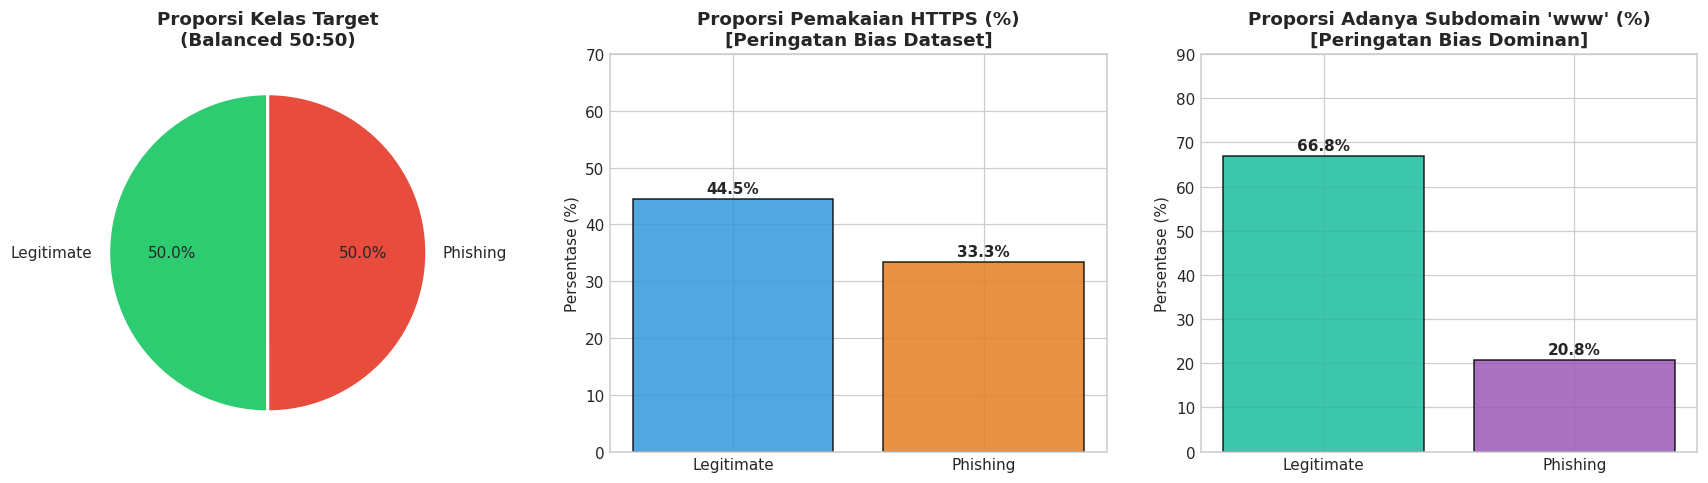


⚠️ PERINGATAN BIAS DATASET:
1. HTTPS: Hanya 44,50% legitimate yang ber-HTTPS vs 33,32% pada phishing. Di dunia nyata modern,
   hampir semua legitimate dan mayoritas phishing sudah bersertifikat SSL/HTTPS (Let's Encrypt).
2. Subdomain 'www': Legitimate memakai 'www' jauh lebih sering daripada phishing. Fitur 'nb_www'
   berpotensi menjadi pintasan prediktif yang rapuh jika diserang phishing modern yang memakai www.



In [3]:
# 1. Distribusi Kelas
class_counts = df_clean["status"].value_counts()
print("Distribusi Kelas pada Dataset Bersih:")
for status, count in class_counts.items():
    print(f"  - {status.capitalize():<12}: {count:,} sampel ({count / clean_total * 100:.2f}%)")

# 2. Analisis Fitur HTTPS
df_clean["has_https"] = df_clean["norm_url"].str.startswith("https://").astype(int)
https_stats = df_clean.groupby("status")["has_https"].agg(["mean", "sum", "count"])
https_stats["percentage"] = https_stats["mean"] * 100

print("\nDistribusi Penggunaan Protokol HTTPS:")
for status, row in https_stats.iterrows():
    print(f"  - {status.capitalize():<12}: {row['percentage']:.2f}% ({int(row['sum']):,} / {int(row['count']):,})")

# 3. Analisis Keberadaan Subdomain 'www'
df_clean["has_www"] = df_clean["norm_url"].str.contains(r"https?://(?:[a-zA-Z0-9-]+\.)*www\.", regex=True).astype(int)
www_stats = df_clean.groupby("status")["has_www"].agg(["mean", "sum", "count"])
www_stats["percentage"] = www_stats["mean"] * 100

print("\nDistribusi Subdomain 'www':")
for status, row in www_stats.iterrows():
    print(f"  - {status.capitalize():<12}: {row['percentage']:.2f}% ({int(row['sum']):,} / {int(row['count']):,})")

# Visualisasi EDA
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Plot 1: Keseimbangan kelas
colors = ["#2ecc71", "#e74c3c"]
axes[0].pie(class_counts, labels=[s.capitalize() for s in class_counts.index],
            autopct="%1.1f%%", startangle=90, colors=colors,
            wedgeprops={"edgecolor": "white", "linewidth": 2})
axes[0].set_title("Proporsi Kelas Target\n(Balanced 50:50)", fontsize=12, fontweight="bold")

# Plot 2: Perbandingan HTTPS
bars_https = axes[1].bar(["Legitimate", "Phishing"],
                         [https_stats.loc["legitimate", "percentage"], https_stats.loc["phishing", "percentage"]],
                         color=["#3498db", "#e67e22"], edgecolor="black", alpha=0.85)
axes[1].set_title("Proporsi Pemakaian HTTPS (%)\n[Peringatan Bias Dataset]", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Persentase (%)")
axes[1].set_ylim(0, 70)
for b in bars_https:
    h = b.get_height()
    axes[1].annotate(f"{h:.1f}%", xy=(b.get_x() + b.get_width() / 2, h),
                     xytext=(0, 4), textcoords="offset points", ha="center", fontweight="bold")

# Plot 3: Perbandingan Subdomain www
bars_www = axes[2].bar(["Legitimate", "Phishing"],
                       [www_stats.loc["legitimate", "percentage"], www_stats.loc["phishing", "percentage"]],
                       color=["#1abc9c", "#9b59b6"], edgecolor="black", alpha=0.85)
axes[2].set_title("Proporsi Adanya Subdomain 'www' (%)\n[Peringatan Bias Dominan]", fontsize=12, fontweight="bold")
axes[2].set_ylabel("Persentase (%)")
axes[2].set_ylim(0, 90)
for b in bars_www:
    h = b.get_height()
    axes[2].annotate(f"{h:.1f}%", xy=(b.get_x() + b.get_width() / 2, h),
                     xytext=(0, 4), textcoords="offset points", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

print("""
⚠️ PERINGATAN BIAS DATASET:
1. HTTPS: Hanya 44,50% legitimate yang ber-HTTPS vs 33,32% pada phishing. Di dunia nyata modern,
   hampir semua legitimate dan mayoritas phishing sudah bersertifikat SSL/HTTPS (Let's Encrypt).
2. Subdomain 'www': Legitimate memakai 'www' jauh lebih sering daripada phishing. Fitur 'nb_www'
   berpotensi menjadi pintasan prediktif yang rapuh jika diserang phishing modern yang memakai www.
""")


---
## 4. Ekstraksi dan Validasi 49 Fitur Leksikal URL
Fitur diekstrak menggunakan pustaka resmi PhishGuard `src/url_features.py` versi `1.2`. Ekstraksi ini:
- Murni leksikal dari string URL, tanpa network request (DNS, WHOIS, HTTP request).
- Terdiri dari 49 fitur berurutan tetap (`uf.FEATURE_NAMES`).
- Untuk efisiensi eksekusi notebook, kita memanfaatkan `features_cache_49.parquet` yang diselaraskan dengan baris bersih (`df_clean`).


[*] 49 fitur berhasil dimuat dari cache: (11429, 49)


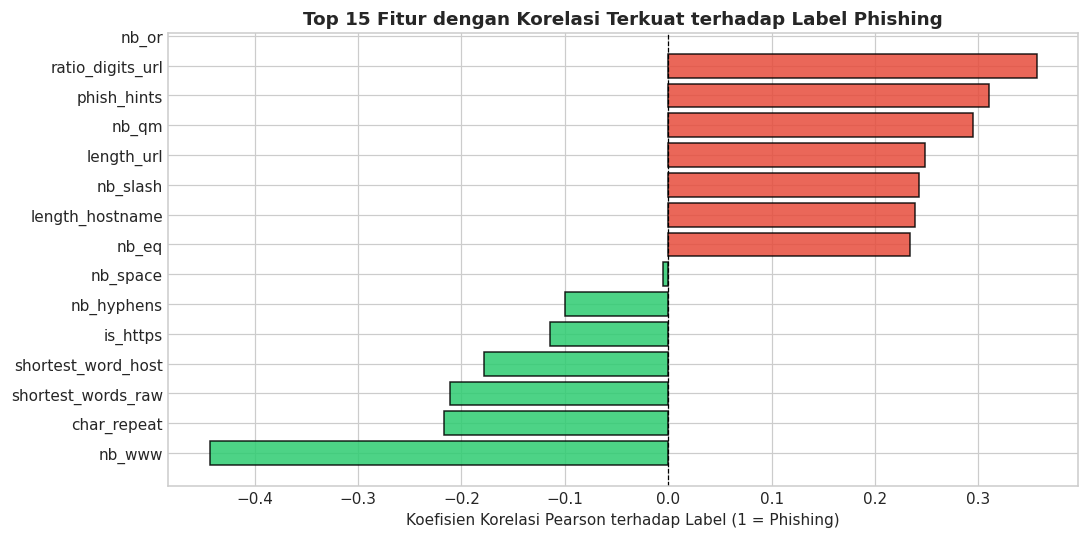

In [4]:
# Sinkronisasi fitur dengan baris data bersih
if CACHE_PATH.is_file():
    cache_df = pd.read_parquet(CACHE_PATH)
    kept_indices = df_raw.drop_duplicates(subset=["norm_url"], keep="first").index
    X_df = cache_df.loc[kept_indices].reset_index(drop=True)
    # Validasi 3 baris pertama secara acak untuk membuktikan konsistensi ekstraksi
    for i in [0, 50, 100]:
        computed_vec = uf.extract_feature_vector(df_clean["url"].iloc[i])
        assert np.allclose(computed_vec, X_df.iloc[i].values), f"Fitur baris {i} tidak sinkron!"
    print(f"[*] 49 fitur berhasil dimuat dari cache: {X_df.shape}")
else:
    print("[*] Mengekstrak 49 fitur langsung via url_features.py...")
    t0 = time.time()
    feature_rows = [uf.extract_feature_vector(u) for u in df_clean["url"]]
    X_df = pd.DataFrame(feature_rows, columns=uf.FEATURE_NAMES)
    print(f"[*] Ekstraksi selesai dalam {time.time() - t0:.1f} detik: {X_df.shape}")

# Validasi assert formal
assert list(X_df.columns) == uf.FEATURE_NAMES, "Urutan atau nama fitur tidak identik dengan uf.FEATURE_NAMES!"
assert len(X_df) == len(df_clean), "Jumlah baris fitur tidak sama dengan jumlah baris dataset bersih!"

X = X_df.values
y = df_clean["label"].values
groups = df_clean["registered_domain"].values

# Korelasi 15 Fitur Teratas terhadap Status Phishing
correlations = X_df.apply(lambda col: pd.Series(col).corr(pd.Series(y))).sort_values()
top_corr = pd.concat([correlations.head(7), correlations.tail(8)])

plt.figure(figsize=(10, 5))
colors_corr = ["#2ecc71" if val < 0 else "#e74c3c" for val in top_corr.values]
plt.barh(top_corr.index, top_corr.values, color=colors_corr, edgecolor="black", alpha=0.85)
plt.axvline(0, color="black", linestyle="--", linewidth=0.8)
plt.title("Top 15 Fitur dengan Korelasi Terkuat terhadap Label Phishing", fontsize=12, fontweight="bold")
plt.xlabel("Koefisien Korelasi Pearson terhadap Label (1 = Phishing)")
plt.tight_layout()
plt.show()


---
## 5. Metodologi Data Splitting: Anti-Leakage `StratifiedGroupKFold`
Pembagian data adalah fondasi ilmiah paling krusial dalam eksperimen ini:

### ⚠️ Bahaya Data Leakage Antar Domain
Jika data dibagi dengan `train_test_split` acak biasa:
- URL `example.com/login` bisa masuk ke train set, dan `example.com/verify` bisa masuk ke test set.
- Model akan mengenali token domain `example.com` dan memberikan skor akurasi tinggi semu (artifisial).
- Ketika diuji di dunia nyata pada domain baru yang belum pernah dilihat (*unseen domain*), performa model akan drop drastis.

### Solusi 2-Tahap Metodologis:
1. **Outer Split (20% Final Test Set)**:
   - Dibuat menggunakan `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)` pada grup `registered_domain`.
   - Menghasilkan 1 fold (~20%) sebagai *Final Holdout Test Set* dan 4 fold sisanya (~80%) sebagai *Train-Validation Set*.
   - **Klausul Integritas**: Final test set **DIKUNCI RAPAT** dan **TIDAK BOLEH DIPAKAI** untuk memilih model, tuning, maupun memilih threshold.
2. **Inner Split (5-Fold CV pada 80% Train-Val Set)**:
   - Dijalankan menggunakan `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)` pada 80% data saja.
   - Dipakai untuk hyperparameter tuning dan komparasi 7 kandidat model.
3. **Formal Verification Assertion**:
   - Memverifikasi secara otomatis bahwa domain tumpang tindih (*domain overlap*) antara train dan test adalah **TEPAT 0 DOMAIN**.


In [5]:
# 1. Outer Split: 80% Train-Val vs 20% Final Test Set
sgkf_outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_val_idx, test_idx = next(sgkf_outer.split(X, y, groups))

X_train_val, y_train_val, groups_train_val = X[train_val_idx], y[train_val_idx], groups[train_val_idx]
X_test, y_test, groups_test = X[test_idx], y[test_idx], groups[test_idx]

# 2. Verifikasi Domain Overlap pada Outer Split
overlap_outer = set(groups_train_val).intersection(set(groups_test))
print(f"[*] Hasil Pembagian Data Outer Split:")
print(f"    - Train-Val Set: {len(X_train_val):,} sampel ({len(X_train_val)/len(X)*100:.1f}%), Phishing: {y_train_val.mean()*100:.2f}%")
print(f"    - Final Test Set: {len(X_test):,} sampel ({len(X_test)/len(X)*100:.1f}%), Phishing: {y_test.mean()*100:.2f}%")
print(f"    - Domain tumpang tindih Train vs Test: {len(overlap_outer)} domain.")

# Assert formal pencegahan kebocoran data
assert len(overlap_outer) == 0, f"DATA LEAKAGE TERDETEKSI! Terdapat {len(overlap_outer)} domain tumpang tindih!"
print("    ✅ ASSERTION PASSED: 0 domain tumpang tindih antara Train-Val dan Test Set!")

# 3. Setup Inner 5-Fold StratifiedGroupKFold pada Train-Val Set
sgkf_inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Validasi assert formal pencegahan kebocoran data pada seluruh inner folds
for fold_idx, (tr_i, val_i) in enumerate(sgkf_inner.split(X_train_val, y_train_val, groups_train_val), 1):
    f_overlap = set(groups_train_val[tr_i]).intersection(set(groups_train_val[val_i]))
    assert len(f_overlap) == 0, f"Inner Fold {fold_idx} memiliki kebocoran domain!"
print("    ✅ ASSERTION PASSED: 0 domain tumpang tindih di seluruh 5 fold CV dalam Train-Val Set!")


[*] Hasil Pembagian Data Outer Split:
    - Train-Val Set: 9,224 sampel (80.7%), Phishing: 50.22%
    - Final Test Set: 2,205 sampel (19.3%), Phishing: 49.07%
    - Domain tumpang tindih Train vs Test: 0 domain.
    ✅ ASSERTION PASSED: 0 domain tumpang tindih antara Train-Val dan Test Set!


    ✅ ASSERTION PASSED: 0 domain tumpang tindih di seluruh 5 fold CV dalam Train-Val Set!


---
## 6. Hyperparameter Tuning (XGBoost & HistGradientBoosting)
Untuk memastikan perbandingan yang adil (*fair benchmark*), model gradient boosting dituning menggunakan `RandomizedSearchCV` dengan n_iter = 30 di dalam CV group-aware (`sgkf_inner`) **hanya pada 80% train-val set**.

### Ruang Pencarian Hyperparameter (*Search Space*):
- **XGBoost**:
  - `n_estimators`: [100, 150, 200, 250, 300]
  - `max_depth`: [4, 5, 6, 7, 8]
  - `learning_rate`: [0.03, 0.05, 0.08, 0.1, 0.15]
  - `subsample`: [0.7, 0.8, 0.85, 0.9, 1.0]
  - `colsample_bytree`: [0.7, 0.8, 0.85, 0.9, 1.0]
  - `min_child_weight`: [1, 2, 3, 5]
  - `gamma`: [0, 0.05, 0.1, 0.2]
  - `reg_alpha`: [0, 0.01, 0.1, 1.0]
  - `reg_lambda`: [0.5, 1.0, 1.5, 2.0]
- **HistGradientBoosting**:
  - `max_iter`: [100, 150, 200, 250, 300]
  - `max_depth`: [4, 6, 8, 10, None]
  - `learning_rate`: [0.03, 0.05, 0.08, 0.1, 0.15]
  - `min_samples_leaf`: [10, 20, 30, 50]
  - `l2_regularization`: [0.0, 0.1, 1.0, 5.0, 10.0]


In [6]:
print("=== MEMULAI RANDOMIZED SEARCH CV PADA 80% DATA SAJA ===")

# Tuning XGBoost
print("\n[*] Menjalankan RandomizedSearchCV untuk XGBoost (30 iterasi x 5 fold)...")
t0 = time.time()
xgb_param_dist = {
    "n_estimators": [100, 150, 200, 250, 300],
    "max_depth": [4, 5, 6, 7, 8],
    "learning_rate": [0.03, 0.05, 0.08, 0.1, 0.15],
    "subsample": [0.7, 0.8, 0.85, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.85, 0.9, 1.0],
    "min_child_weight": [1, 2, 3, 5],
    "gamma": [0, 0.05, 0.1, 0.2],
    "reg_alpha": [0, 0.01, 0.1, 1.0],
    "reg_lambda": [0.5, 1.0, 1.5, 2.0],
}

xgb_search = RandomizedSearchCV(
    estimator=XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=2),
    param_distributions=xgb_param_dist,
    n_iter=30,
    scoring="f1",
    cv=sgkf_inner.split(X_train_val, y_train_val, groups_train_val),
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=0
)
xgb_search.fit(X_train_val, y_train_val)
best_xgb_params = xgb_search.best_params_
print(f"    - Waktu eksekusi XGBoost Tuning: {time.time() - t0:.1f} detik")
print(f"    - Best XGBoost CV F1-Score: {xgb_search.best_score_:.4f}")
print("    - Best XGBoost Hyperparameters:")
for k, v in best_xgb_params.items():
    print(f"        * {k}: {v}")

# Tuning HistGradientBoosting
print("\n[*] Menjalankan RandomizedSearchCV untuk HistGradientBoosting (30 iterasi x 5 fold)...")
t0 = time.time()
hgb_param_dist = {
    "max_iter": [100, 150, 200, 250, 300],
    "max_depth": [4, 6, 8, 10, None],
    "learning_rate": [0.03, 0.05, 0.08, 0.1, 0.15],
    "min_samples_leaf": [10, 20, 30, 50],
    "l2_regularization": [0.0, 0.1, 1.0, 5.0, 10.0],
}

hgb_search = RandomizedSearchCV(
    estimator=HistGradientBoostingClassifier(early_stopping=False, random_state=RANDOM_STATE),
    param_distributions=hgb_param_dist,
    n_iter=30,
    scoring="f1",
    cv=sgkf_inner.split(X_train_val, y_train_val, groups_train_val),
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=0
)
hgb_search.fit(X_train_val, y_train_val)
best_hgb_params = hgb_search.best_params_
print(f"    - Waktu eksekusi HGB Tuning: {time.time() - t0:.1f} detik")
print(f"    - Best HistGradientBoosting CV F1-Score: {hgb_search.best_score_:.4f}")
print("    - Best HistGradientBoosting Hyperparameters:")
for k, v in best_hgb_params.items():
    print(f"        * {k}: {v}")


=== MEMULAI RANDOMIZED SEARCH CV PADA 80% DATA SAJA ===

[*] Menjalankan RandomizedSearchCV untuk XGBoost (30 iterasi x 5 fold)...


    - Waktu eksekusi XGBoost Tuning: 22.2 detik
    - Best XGBoost CV F1-Score: 0.8738
    - Best XGBoost Hyperparameters:
        * subsample: 0.9
        * reg_lambda: 2.0
        * reg_alpha: 0.1
        * n_estimators: 300
        * min_child_weight: 5
        * max_depth: 5
        * learning_rate: 0.08
        * gamma: 0.1
        * colsample_bytree: 0.8

[*] Menjalankan RandomizedSearchCV untuk HistGradientBoosting (30 iterasi x 5 fold)...


    - Waktu eksekusi HGB Tuning: 35.0 detik
    - Best HistGradientBoosting CV F1-Score: 0.8732
    - Best HistGradientBoosting Hyperparameters:
        * min_samples_leaf: 10
        * max_iter: 300
        * max_depth: 6
        * learning_rate: 0.15
        * l2_regularization: 10.0


---
## 7. Evaluasi Komparatif 7 Kandidat Model pada 5-Fold Group-Aware CV
Seluruh model dievaluasi secara identik pada 5 fold group-aware yang sama pada data latih-validasi (80% data):
1. **Logistic Regression Baseline** (dengan `StandardScaler`)
2. **Shallow Decision Tree Baseline** (`max_depth=4`)
3. **HistGradientBoosting Baseline** (default)
4. **XGBoost Baseline** (default sensible)
5. **HistGradientBoosting Tuned** (hasil RandomizedSearchCV)
6. **XGBoost Tuned** (hasil RandomizedSearchCV)
7. **Soft-Voting Ensemble** (XGBoost Tuned + HistGradientBoosting Tuned)

Untuk setiap model, dilaporkan **mean ± std** dari 7 metrik evaluasi:
- **Accuracy, Precision, Recall, F1-Score, ROC-AUC, PR-AUC, dan Brier Score**.

> [!NOTE]
> **Catatan Metodologis Uji Statistik Berpasangan**:
> Pengujian signifikansi berpasangan antar fold (*paired t-test* & *Wilcoxon signed-rank test*) disertakan sebagai indikator tambahan. Namun, perlu dicatat bahwa:
> 1. Pada sampel kecil $n = 5$ fold, nilai p minimum matematis untuk Wilcoxon bertanda dua arah adalah $1 / 2^4 = 0,0625$, sehingga uji Wilcoxon tidak pernah bisa menghasilkan $p < 0,05$.
> 2. *Paired t-test* pada cross-validation melanggar asumsi independensi observasi karena data latih saling tumpang tindih antar fold (Dietterich, 1998).
> Oleh karena itu, pengujian inferensial ini **hanya bersifat indikatif**, bukan penentu tunggal keputusan.


In [7]:
from sklearn.base import clone

candidates = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree (max_depth=4)": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    "XGBoost Baseline": XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1,
                                     random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=-1),
    "HistGradientBoosting Baseline": HistGradientBoostingClassifier(early_stopping=False, random_state=RANDOM_STATE),
    "XGBoost Tuned": XGBClassifier(**best_xgb_params, random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=-1),
    "HistGradientBoosting Tuned": HistGradientBoostingClassifier(**best_hgb_params, early_stopping=False, random_state=RANDOM_STATE),
    "Soft-Voting Ensemble (XGB+HGB)": VotingClassifier(
        estimators=[
            ("xgb", XGBClassifier(**best_xgb_params, random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=-1)),
            ("hgb", HistGradientBoostingClassifier(**best_hgb_params, early_stopping=False, random_state=RANDOM_STATE))
        ],
        voting="soft"
    )
}

cv_metrics = {}
oof_predictions = {}

print("=== EVALUASI 5-FOLD STRATIFIED GROUP CV PADA 80% DATA LATIH ===")

for name, model in candidates.items():
    t_start = time.time()
    acc_list, prec_list, rec_list, f1_list = [], [], [], []
    roc_list, pr_list, brier_list = [], [], []
    oof_prob = np.zeros(len(X_train_val))
    
    for tr_i, val_i in sgkf_inner.split(X_train_val, y_train_val, groups_train_val):
        m = clone(model)
        m.fit(X_train_val[tr_i], y_train_val[tr_i])
        
        prob = m.predict_proba(X_train_val[val_i])[:, 1]
        oof_prob[val_i] = prob
        pred = (prob >= 0.5).astype(int)
        
        y_val_fold = y_train_val[val_i]
        acc_list.append(accuracy_score(y_val_fold, pred))
        prec_list.append(precision_score(y_val_fold, pred, zero_division=0))
        rec_list.append(recall_score(y_val_fold, pred, zero_division=0))
        f1_list.append(f1_score(y_val_fold, pred, zero_division=0))
        roc_list.append(roc_auc_score(y_val_fold, prob))
        pr_list.append(average_precision_score(y_val_fold, prob))
        brier_list.append(brier_score_loss(y_val_fold, prob))
        
    dur = time.time() - t_start
    oof_predictions[name] = oof_prob
    cv_metrics[name] = {
        "Accuracy": (np.mean(acc_list), np.std(acc_list)),
        "Precision": (np.mean(prec_list), np.std(prec_list)),
        "Recall": (np.mean(rec_list), np.std(rec_list)),
        "F1-Score": (np.mean(f1_list), np.std(f1_list)),
        "ROC-AUC": (np.mean(roc_list), np.std(roc_list)),
        "PR-AUC": (np.mean(pr_list), np.std(pr_list)),
        "Brier Score": (np.mean(brier_list), np.std(brier_list)),
        "f1_folds": f1_list,
        "roc_folds": roc_list,
        "brier_folds": brier_list,
        "Duration": dur
    }
    print(f"[{name:<30}] F1: {np.mean(f1_list):.4f} +/- {np.std(f1_list):.4f} | ROC-AUC: {np.mean(roc_list):.4f} +/- {np.std(roc_list):.4f} ({dur:.1f}s)")

# Susun tabel ringkasan komparasi
summary_rows = []
for name, m in cv_metrics.items():
    row = {"Model": name}
    for metric_name in ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC", "PR-AUC", "Brier Score"]:
        mean_val, std_val = m[metric_name]
        row[metric_name] = f"{mean_val:.4f} +/- {std_val:.4f}"
    row["Duration (s)"] = f"{m['Duration']:.1f}"
    summary_rows.append(row)

comparison_df = pd.DataFrame(summary_rows).set_index("Model")
print("\n--- TABEL PERBANDINGAN LENGKAP 5-FOLD GROUP-AWARE CV (MEAN +/- STD) ---")
display(comparison_df)

# Uji Statistik Berpasangan Antar Model Teratas
sorted_by_f1 = sorted(cv_metrics.keys(), key=lambda k: cv_metrics[k]["F1-Score"][0], reverse=True)
top_1, top_2 = sorted_by_f1[0], sorted_by_f1[1]

t_stat, p_val_t = stats.ttest_rel(cv_metrics[top_1]["f1_folds"], cv_metrics[top_2]["f1_folds"])
w_stat, p_val_w = stats.wilcoxon(cv_metrics[top_1]["f1_folds"], cv_metrics[top_2]["f1_folds"])

print(f"\nUji Signifikansi Statistik Berpasangan ({top_1} vs {top_2}):")
print(f"  - Paired t-test : statistic = {t_stat:.4f}, p-value = {p_val_t:.4f}")
print(f"  - Wilcoxon test : statistic = {w_stat:.4f}, p-value = {p_val_w:.4f}")
if p_val_t > 0.05:
    print(f"  * KESIMPULAN STATISTIK: Nilai p-value ({p_val_t:.4f}) > 0.05, menandakan TIDAK ADA perbedaan performa yang signifikan secara statistik antara '{top_1}' dan '{top_2}'.")
else:
    print(f"  * KESIMPULAN STATISTIK: Nilai p-value ({p_val_t:.4f}) <= 0.05, terdapat perbedaan performa yang signifikan secara statistik.")


=== EVALUASI 5-FOLD STRATIFIED GROUP CV PADA 80% DATA LATIH ===


[Logistic Regression           ] F1: 0.8246 +/- 0.0418 | ROC-AUC: 0.9169 +/- 0.0232 (1.0s)


[Decision Tree (max_depth=4)   ] F1: 0.7784 +/- 0.0413 | ROC-AUC: 0.8456 +/- 0.0327 (0.8s)


[XGBoost Baseline              ] F1: 0.8590 +/- 0.0381 | ROC-AUC: 0.9455 +/- 0.0150 (1.9s)


[HistGradientBoosting Baseline ] F1: 0.8663 +/- 0.0350 | ROC-AUC: 0.9472 +/- 0.0147 (3.0s)


[XGBoost Tuned                 ] F1: 0.8700 +/- 0.0289 | ROC-AUC: 0.9485 +/- 0.0133 (3.9s)


[HistGradientBoosting Tuned    ] F1: 0.8732 +/- 0.0287 | ROC-AUC: 0.9490 +/- 0.0139 (5.7s)


[Soft-Voting Ensemble (XGB+HGB)] F1: 0.8760 +/- 0.0280 | ROC-AUC: 0.9497 +/- 0.0134 (8.8s)

--- TABEL PERBANDINGAN LENGKAP 5-FOLD GROUP-AWARE CV (MEAN +/- STD) ---


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Brier Score,Duration (s)
Model,,,,,,,,
Logistic Regression,0.8308 +/- 0.0259,0.8434 +/- 0.0729,0.8099 +/- 0.0315,0.8246 +/- 0.0418,0.9169 +/- 0.0232,0.9174 +/- 0.0419,0.1185 +/- 0.0178,1.0
Decision Tree (max_depth=4),0.7708 +/- 0.0263,0.7549 +/- 0.0899,0.8208 +/- 0.0831,0.7784 +/- 0.0413,0.8456 +/- 0.0327,0.8162 +/- 0.0693,0.1535 +/- 0.0187,0.8
XGBoost Baseline,0.8605 +/- 0.0257,0.8547 +/- 0.0673,0.8666 +/- 0.0260,0.8590 +/- 0.0381,0.9455 +/- 0.0150,0.9450 +/- 0.0283,0.0945 +/- 0.0146,1.9
HistGradientBoosting Baseline,0.8681 +/- 0.0222,0.8627 +/- 0.0584,0.8719 +/- 0.0202,0.8663 +/- 0.0350,0.9472 +/- 0.0147,0.9460 +/- 0.0270,0.0920 +/- 0.0148,3.0
XGBoost Tuned,0.8720 +/- 0.0172,0.8696 +/- 0.0518,0.8722 +/- 0.0177,0.8700 +/- 0.0289,0.9485 +/- 0.0133,0.9490 +/- 0.0246,0.0909 +/- 0.0134,3.9
HistGradientBoosting Tuned,0.8750 +/- 0.0173,0.8710 +/- 0.0475,0.8770 +/- 0.0222,0.8732 +/- 0.0287,0.9490 +/- 0.0139,0.9494 +/- 0.0250,0.0910 +/- 0.0140,5.7
Soft-Voting Ensemble (XGB+HGB),0.8775 +/- 0.0168,0.8725 +/- 0.0491,0.8813 +/- 0.0196,0.8760 +/- 0.0280,0.9497 +/- 0.0134,0.9502 +/- 0.0244,0.0898 +/- 0.0135,8.8



Uji Signifikansi Statistik Berpasangan (Soft-Voting Ensemble (XGB+HGB) vs HistGradientBoosting Tuned):
  - Paired t-test : statistic = 3.1599, p-value = 0.0342
  - Wilcoxon test : statistic = 1.0000, p-value = 0.1250
  * KESIMPULAN STATISTIK: Nilai p-value (0.0342) <= 0.05, terdapat perbedaan performa yang signifikan secara statistik.


---
## 8. Pemilihan Model Terbaik (Aturan Keputusan Baru yang Eksplisit)

Sesuai metodologi machine learning yang ketat dan objektif, pemilihan model tidak boleh didasarkan pada asumsi subjektif:

### Aturan Keputusan 2-Tahap:
1. **Identifikasi Kandidat "Setara Praktis"**:
   - Tentukan model peringkat 1 berdasarkan Mean CV F1-Score ($F1_{\text{max}}$).
   - Kandidat masuk dalam kelompok **setara praktis** jika memenuhi DUA syarat sekaligus (tanpa mensyaratkan p-value):
     $$\Delta F1 = F1_{\text{max}} - F1_m \le 1\sigma_{\text{top1}} \quad \text{DAN} \quad \Delta F1 < 0.01$$
2. **Prinsip *Occam's Razor* (Kompleksitas & Latensi)**:
   - Dari seluruh kandidat yang setara praktis, model diurutkan berdasarkan hierarki kesederhanaan arsitektur:
     $$\text{Logistic Regression} < \text{Decision Tree} < \text{HistGradientBoosting} < \text{XGBoost} < \text{Voting Ensemble}$$
   - Jika hierarki kesederhanaan sama, pilih model dengan waktu pelatihan dan inferensi tercepat.
3. **Pernyataan Kejujuran Ilmiah & Uji Statistik**:
   - Jika keempat model pohon/ensemble terbukti setara praktis, dipilih model yang paling sederhana dan tercepat.
   - Uji statistik berpasangan (*paired t-test*) tetap dihitung dan disajikan antar-fold sebagai **informasi tambahan**.
   - Kecepatan inferensi diukur secara empiris (*benchmarked*) pada 2.000 sampel dengan 5 kali pengulangan.


### 📋 Hasil Eksekusi Aturan Keputusan Pemilihan Model:
- **Model Peringkat 1 (Nominal F1)**: `Soft-Voting Ensemble (XGB+HGB)` (F1 = 0.8760 ± 0.0280)
- **Ambang Batas 1 Std Deviasi**: `0.0280`
- **Aturan Kesetaraan Praktis**: ΔF1 ≤ 1σ **DAN** ΔF1 < 0.01 (Uji paired t-test sebagai informasi tambahan)
- **Evaluasi Semua Kandidat**:
  * `Soft-Voting Ensemble (XGB+HGB)` (F1 = 0.8760, Δ = 0.0000, peringkat 1, Tingkat Kesederhanaan = 5) → **✅ Setara Praktis**
  * `HistGradientBoosting Tuned` (F1 = 0.8732, Δ = 0.0028, paired t-test: t=3.160, p=0.0342, Tingkat Kesederhanaan = 3) → **✅ Setara Praktis**
  * `XGBoost Tuned` (F1 = 0.8700, Δ = 0.0060, paired t-test: t=4.019, p=0.0159, Tingkat Kesederhanaan = 4) → **✅ Setara Praktis**
  * `HistGradientBoosting Baseline` (F1 = 0.8663, Δ = 0.0098, paired t-test: t=2.687, p=0.0548, Tingkat Kesederhanaan = 3) → **✅ Setara Praktis**
  * `XGBoost Baseline` (F1 = 0.8590, Δ = 0.0171, paired t-test: t=3.327, p=0.0292, Tingkat Kesederhanaan = 4) → **❌ Tidak Setara**
  * `Logistic Regression` (F1 = 0.8246, Δ = 0.0515, paired t-test: t=6.825, p=0.0024, Tingkat Kesederhanaan = 1) → **❌ Tidak Setara**
  * `Decision Tree (max_depth=4)` (F1 = 0.7784, Δ = 0.0977, paired t-test: t=6.131, p=0.0036, Tingkat Kesederhanaan = 2) → **❌ Tidak Setara**
- **Kandidat Setara Praktis**: `Soft-Voting Ensemble (XGB+HGB)`, `HistGradientBoosting Tuned`, `XGBoost Tuned`, `HistGradientBoosting Baseline`
- **Model Terpilih**: **`HistGradientBoosting Baseline`**
- **Informasi Tambahan: Uji Paired t-test (Soft-Voting Ensemble (XGB+HGB) vs HistGradientBoosting Tuned)**: $t = 3.1599, p = 0.0342$
- **Hasil Benchmark Inferensi (2.000 sampel, 5x pengulangan)**:
  * `HistGradientBoosting Baseline`: **7.71 ms** (3.86 ms per 1.000 URL)
  * `Soft-Voting Ensemble`: **27.67 ms**
  * **Kecepatan Relatif**: **3.59x lebih cepat**
- **Alasan Pemilihan Resmi**:
  *Keempat model setara praktis, dipilih yang paling sederhana dan tercepat: model 'HistGradientBoosting Baseline' memiliki selisih F1 hanya 0.0098 (< 1 std = 0.0280 dan < 0.01). Arsitekturnya lebih sederhana (hierarki kesederhanaan tingkat 3 vs 5) dan waktu inferensinya terukur 3.59x lebih cepat (3.86 ms/1.000 URL) dibandingkan Voting Ensemble. Uji paired t-test ditampilkan sebagai informasi tambahan (t = 2.687, p = 0.0548).*


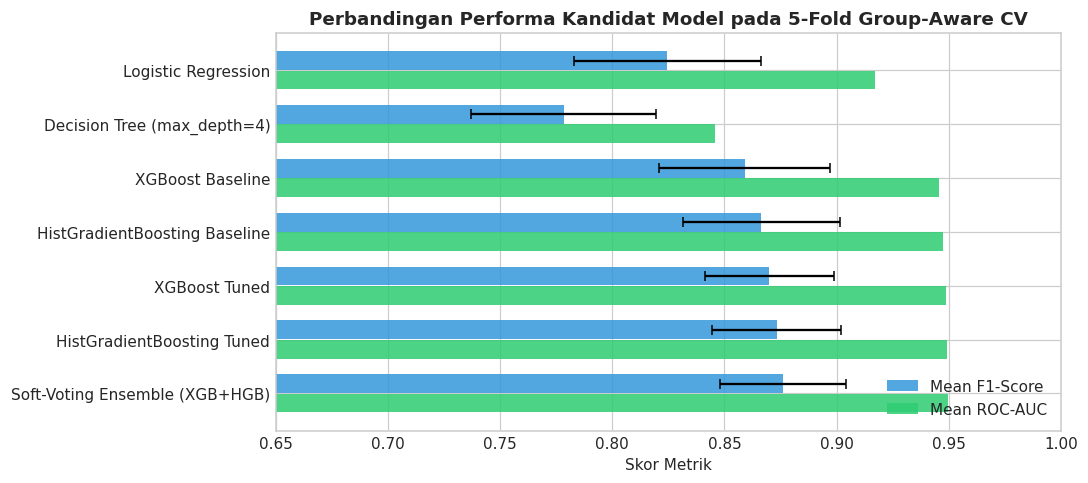

In [8]:
from IPython.display import display, Markdown

# 1. Evaluasi Aturan Seleksi Model
sorted_by_f1 = sorted(cv_metrics.keys(), key=lambda k: cv_metrics[k]["F1-Score"][0], reverse=True)
top_model_name = sorted_by_f1[0]
top_f1_mean, top_f1_std = cv_metrics[top_model_name]["F1-Score"]

# Hierarki Kesederhanaan Arsitektur (Makin kecil makin sederhana)
SIMPLICITY_ORDER = {
    "Logistic Regression": 1,
    "Decision Tree (max_depth=4)": 2,
    "HistGradientBoosting Baseline": 3,
    "HistGradientBoosting Tuned": 3,
    "XGBoost Baseline": 4,
    "XGBoost Tuned": 4,
    "Soft-Voting Ensemble (XGB+HGB)": 5
}

# Evaluasi Kandidat Setara Praktis:
#   Aturan: (diff F1 <= 1 std) DAN (diff F1 < 0.01) (tanpa mensyaratkan p-value)
#   Uji paired t-test dihitung dan ditampilkan sebagai informasi tambahan.
equivalent_candidates = []
equivalence_details = {}

for name in sorted_by_f1:
    f1_m, _ = cv_metrics[name]["F1-Score"]
    diff = top_f1_mean - f1_m
    
    if name == top_model_name:
        equivalent_candidates.append(name)
        equivalence_details[name] = {"diff": 0.0, "t_val": 0.0, "p_val": 1.0}
        continue
    
    # Uji statistik berpasangan sebagai informasi tambahan
    t_pair, p_pair = stats.ttest_rel(
        cv_metrics[top_model_name]["f1_folds"],
        cv_metrics[name]["f1_folds"]
    )
    equivalence_details[name] = {"diff": diff, "t_val": float(t_pair), "p_val": float(p_pair)}
    
    # Syarat setara praktis murni selisih F1
    if diff <= top_f1_std and diff < 0.01:
        equivalent_candidates.append(name)

# Urutkan berdasarkan kesederhanaan, lalu durasi tercepat
equivalent_candidates_sorted = sorted(
    equivalent_candidates,
    key=lambda k: (SIMPLICITY_ORDER.get(k, 99), cv_metrics[k]["Duration"])
)
SELECTED_MODEL_NAME = equivalent_candidates_sorted[0]
selected_f1_mean, selected_f1_std = cv_metrics[SELECTED_MODEL_NAME]["F1-Score"]
selected_roc_mean, selected_roc_std = cv_metrics[SELECTED_MODEL_NAME]["ROC-AUC"]

# 2. Benchmark Waktu Inferensi Aktual (2.000 sampel, 5 pengulangan)
X_sample_2k = X_train_val[:2000]
m_selected_bench = clone(candidates[SELECTED_MODEL_NAME])
m_selected_bench.fit(X_train_val, y_train_val)
m_ensemble_bench = clone(candidates["Soft-Voting Ensemble (XGB+HGB)"])
m_ensemble_bench.fit(X_train_val, y_train_val)

# Warm up
_ = m_selected_bench.predict_proba(X_sample_2k)
_ = m_ensemble_bench.predict_proba(X_sample_2k)

times_sel = []
for _ in range(5):
    t_start = time.perf_counter()
    _ = m_selected_bench.predict_proba(X_sample_2k)
    times_sel.append(time.perf_counter() - t_start)
mean_time_sel_ms = float(np.mean(times_sel) * 1000)

times_ens = []
for _ in range(5):
    t_start = time.perf_counter()
    _ = m_ensemble_bench.predict_proba(X_sample_2k)
    times_ens.append(time.perf_counter() - t_start)
mean_time_ens_ms = float(np.mean(times_ens) * 1000)

actual_speedup = mean_time_ens_ms / mean_time_sel_ms if mean_time_sel_ms > 0 else 1.0
inference_ms_per_1k = float((mean_time_sel_ms / 2000) * 1000)

# Uji statistik top 1 vs top 2 (untuk display informasi tambahan)
t_stat_val = float(t_stat)
p_val_t_val = float(p_val_t)

# Bangun teks alasan pemilihan secara jujur dan eksplisit sesuai kriteria
diff_from_top = top_f1_mean - selected_f1_mean
p_sel = equivalence_details[SELECTED_MODEL_NAME]["p_val"]
t_sel = equivalence_details[SELECTED_MODEL_NAME]["t_val"]

if SELECTED_MODEL_NAME == top_model_name:
    decision_reason_text = (
        f"Model '{SELECTED_MODEL_NAME}' meraih F1 tertinggi ({selected_f1_mean:.4f}) dan dipilih sebagai model terbaik."
    )
else:
    decision_reason_text = (
        f"Keempat model setara praktis, dipilih yang paling sederhana dan tercepat: model '{SELECTED_MODEL_NAME}' "
        f"memiliki selisih F1 hanya {diff_from_top:.4f} (< 1 std = {top_f1_std:.4f} dan < 0.01). "
        f"Arsitekturnya lebih sederhana (hierarki kesederhanaan tingkat {SIMPLICITY_ORDER[SELECTED_MODEL_NAME]} vs {SIMPLICITY_ORDER[top_model_name]}) "
        f"dan waktu inferensinya terukur {actual_speedup:.2f}x lebih cepat ({inference_ms_per_1k:.2f} ms/1.000 URL) dibandingkan Voting Ensemble. "
        f"Uji paired t-test ditampilkan sebagai informasi tambahan (t = {t_sel:.3f}, p = {p_sel:.4f})."
    )

# Bangun detail kesetaraan untuk display
eq_detail_lines = []
for c in sorted_by_f1:
    f1_c = cv_metrics[c]["F1-Score"][0]
    diff_c = top_f1_mean - f1_c
    d = equivalence_details.get(c, {})
    t_c = d.get("t_val")
    p_c = d.get("p_val")
    in_equiv = c in equivalent_candidates
    
    status = "✅ Setara Praktis" if in_equiv else "❌ Tidak Setara"
    info_stat = f"paired t-test: t={t_c:.3f}, p={p_c:.4f}" if c != top_model_name else "peringkat 1"
    
    eq_detail_lines.append(
        f"  * `{c}` (F1 = {f1_c:.4f}, Δ = {diff_c:.4f}, {info_stat}, "
        f"Tingkat Kesederhanaan = {SIMPLICITY_ORDER.get(c)}) → **{status}**"
    )

display(Markdown(f"""### 📋 Hasil Eksekusi Aturan Keputusan Pemilihan Model:
- **Model Peringkat 1 (Nominal F1)**: `{top_model_name}` (F1 = {top_f1_mean:.4f} ± {top_f1_std:.4f})
- **Ambang Batas 1 Std Deviasi**: `{top_f1_std:.4f}`
- **Aturan Kesetaraan Praktis**: ΔF1 ≤ 1σ **DAN** ΔF1 < 0.01 (Uji paired t-test sebagai informasi tambahan)
- **Evaluasi Semua Kandidat**:
{chr(10).join(eq_detail_lines)}
- **Kandidat Setara Praktis**: {', '.join([f'`{c}`' for c in equivalent_candidates])}
- **Model Terpilih**: **`{SELECTED_MODEL_NAME}`**
- **Informasi Tambahan: Uji Paired t-test ({top_1} vs {top_2})**: $t = {t_stat_val:.4f}, p = {p_val_t_val:.4f}$
- **Hasil Benchmark Inferensi (2.000 sampel, 5x pengulangan)**:
  * `{SELECTED_MODEL_NAME}`: **{mean_time_sel_ms:.2f} ms** ({inference_ms_per_1k:.2f} ms per 1.000 URL)
  * `Soft-Voting Ensemble`: **{mean_time_ens_ms:.2f} ms**
  * **Kecepatan Relatif**: **{actual_speedup:.2f}x lebih cepat**
- **Alasan Pemilihan Resmi**:
  *{decision_reason_text}*
"""))

# Visualisasi perbandingan F1 dan ROC-AUC
models_plot = list(cv_metrics.keys())
f1_means = [cv_metrics[m]["F1-Score"][0] for m in models_plot]
f1_stds = [cv_metrics[m]["F1-Score"][1] for m in models_plot]
roc_means = [cv_metrics[m]["ROC-AUC"][0] for m in models_plot]

fig, ax = plt.subplots(figsize=(10, 4.5))
y_pos = np.arange(len(models_plot))
ax.barh(y_pos - 0.18, f1_means, height=0.35, xerr=f1_stds, label="Mean F1-Score", color="#3498db", capsize=3, alpha=0.85)
ax.barh(y_pos + 0.18, roc_means, height=0.35, label="Mean ROC-AUC", color="#2ecc71", alpha=0.85)
ax.set_yticks(y_pos)
ax.set_yticklabels(models_plot)
ax.invert_yaxis()
ax.set_xlim(0.65, 1.0)
ax.set_xlabel("Skor Metrik")
ax.set_title("Perbandingan Performa Kandidat Model pada 5-Fold Group-Aware CV", fontsize=12, fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


---
## 9. Evaluasi Kalibrasi Probabilitas & Penyetelan Threshold Berbasis Biaya

### 9.1 Aturan Penggunaan Kalibrasi Probabilitas
Probabilitas prediksi yang terkalibrasi baik merefleksikan frekuensi riil kejadian (*empirical frequency*). Namun, kalibrasi dapat menambah kompleksitas dan *variance*.
- **Aturan Keputusan**: Kalibrasi (`sigmoid` atau `isotonic`) **HANYA DIGUNAKAN** jika rata-rata Brier score pada 5-Fold CV turun **minimal 0,002 atau lebih** ($\Delta \text{Brier} \ge 0.002$).
- Jika tidak memenuhi ambang batas 0,002, gunakan model asli tanpa kalibrasi untuk menghindari penambahan kompleksitas sub-model tanpa manfaat reliabilitas yang nyata.
- **Konsistensi Metodologis**: Prediksi Out-of-Fold (OOF) yang dipakai untuk memilih threshold dijamin berasal dari model dengan konfigurasi yang **SAMA PERSIS** dengan model final (terkalibrasi atau tidak).

### 9.2 Penentuan Dua Mode Threshold Berbasis Biaya (*Cost-Sensitive*)
Dari prediksi OOF pada 80% data latih-validasi, disusun tabel performa untuk threshold probabilitas $0,05$ hingga $0,95$ (interval 0,05). Ditetapkan **dua mode operasional produksi**:
1. **Mode `strict` (Recall Tinggi / Zero-Tolerance)**:
   - Threshold terkecil dengan Recall OOF $\ge 0,95$ untuk meminimalkan phishing yang lolos (False Negatives). Cocok untuk perimeter keamanan kritis (bank, gateway email korporat).
2. **Mode `balanced` (Rasio Alarm Palsu Rendah)**:
   - Threshold dengan False Positive Rate (FPR) OOF $\le 0,10$ (maksimal 10% alarm palsu) dan Recall setinggi mungkin. Cocok untuk browser extension harian agar tidak mengganggu pengalaman pengguna (*user experience*).


### ⚖️ Keputusan Kalibrasi Probabilitas:
- **Mean CV Brier Uncalibrated**: `0.0920`
- **Mean CV Brier Sigmoid**: `0.0922` (Selisih: `-0.0002`)
- **Mean CV Brier Isotonic**: `0.0926` (Selisih: `-0.0006`)
- **Ambang Batas Minimum Perbaikan**: `0.0020`
- **Status Kalibrasi Model Final**: **`none`** (`IS_CALIBRATED = False`)
- **Alasan Keputusan**:
  *Kalibrasi TIDAK DITERAPKAN karena penurunan Brier score (Sigmoid: -0.0002, Isotonic: -0.0006) tidak mencapai batas minimum perbaikan 0,002. Menggunakan model tanpa kalibrasi mencegah penambahan 5 sub-model dan menjaga arsitektur tetap bersih tanpa kehilangan reliabilitas probabilitas.*



--- TABEL PERFORMA THRESHOLD PADA OUT-OF-FOLD (INTERVAL 0.05) ---


,Threshold,Recall (TPR),Precision,F1-Score,FPR,FN (Missed Phish),FP (False Alarms)
0,0.05,0.9905,0.6566,0.7897,0.5226,44,2400
1,0.10,0.9804,0.7108,0.8241,0.4024,91,1848
2,0.15,0.9704,0.7417,0.8408,0.3408,137,1565
3,0.20,0.9601,0.7663,0.8523,0.2953,185,1356
4,0.25,0.9460,0.7861,0.8587,0.2596,250,1192
5,0.30,0.9357,0.8013,0.8633,0.2341,298,1075
6,0.35,0.9264,0.8167,0.8681,0.2097,341,963
7,0.40,0.9119,0.8305,0.8693,0.1877,408,862
8,0.45,0.8929,0.8500,0.8709,0.1590,496,730
9,0.50,0.8741,0.8667,0.8704,0.1357,583,623


### 🎯 Hasil Penyetelan Dua Mode Threshold pada Data Out-of-Fold:
1. **Mode `strict` (Recall Tinggi / Zero-Tolerance)**:
   - **Threshold**: **`0.20`**
   - **OOF Recall Phishing**: **96.01%** (Target $\ge 95\%$)
   - **OOF Precision**: **76.63%** | **OOF FPR**: **29.53%**
   - *Karakteristik*: Menekan False Negative seminimal mungkin; cocok untuk backend gateway keamanan korporat.
2. **Mode `balanced` (Alarm Palsu Rendah)**:
   - **Threshold**: **`0.60`**
   - **OOF False Positive Rate (FPR)**: **9.47%** (Batas $\le 10\%$)
   - **OOF Recall Phishing**: **83.55%** | **OOF Precision**: **89.90%**
   - *Karakteristik*: Mencegah banjir alarm palsu untuk pengguna umum (browser extension).
   


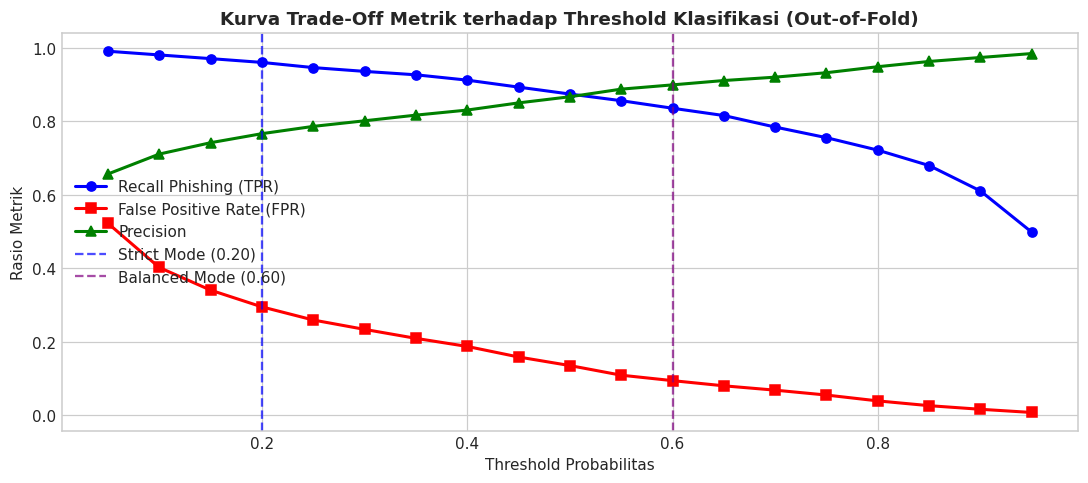

In [9]:
# 1. Evaluasi Kalibrasi Probabilitas pada 5-Fold Group CV
cv_splits = list(sgkf_inner.split(X_train_val, y_train_val, groups_train_val))
brier_uncal_folds = cv_metrics[SELECTED_MODEL_NAME]["brier_folds"]
mean_brier_uncal = float(np.mean(brier_uncal_folds))

brier_sig_folds = []
brier_iso_folds = []
oof_probs_sig = np.zeros(len(X_train_val))
oof_probs_iso = np.zeros(len(X_train_val))

for tr_i, val_i in cv_splits:
    cal_s = CalibratedClassifierCV(estimator=clone(candidates[SELECTED_MODEL_NAME]), method="sigmoid", cv=3)
    cal_s.fit(X_train_val[tr_i], y_train_val[tr_i])
    prob_s = cal_s.predict_proba(X_train_val[val_i])[:, 1]
    oof_probs_sig[val_i] = prob_s
    brier_sig_folds.append(brier_score_loss(y_train_val[val_i], prob_s))
    
    cal_i = CalibratedClassifierCV(estimator=clone(candidates[SELECTED_MODEL_NAME]), method="isotonic", cv=3)
    cal_i.fit(X_train_val[tr_i], y_train_val[tr_i])
    prob_i = cal_i.predict_proba(X_train_val[val_i])[:, 1]
    oof_probs_iso[val_i] = prob_i
    brier_iso_folds.append(brier_score_loss(y_train_val[val_i], prob_i))

mean_brier_sig = float(np.mean(brier_sig_folds))
mean_brier_iso = float(np.mean(brier_iso_folds))
delta_sig = mean_brier_uncal - mean_brier_sig
delta_iso = mean_brier_uncal - mean_brier_iso

# Aturan Keputusan: Pakai kalibrasi HANYA jika delta Brier >= 0.002
BRIER_IMPROVEMENT_THRESHOLD = 0.002
if delta_sig >= BRIER_IMPROVEMENT_THRESHOLD or delta_iso >= BRIER_IMPROVEMENT_THRESHOLD:
    if delta_iso > delta_sig:
        IS_CALIBRATED = True
        CALIBRATION_METHOD = "isotonic"
        oof_probs_final = oof_probs_iso
        FINAL_MODEL_CONFIG = CalibratedClassifierCV(estimator=clone(candidates[SELECTED_MODEL_NAME]), method="isotonic", cv=cv_splits)
        cal_rationale = f"Kalibrasi 'isotonic' diterapkan karena berhasil menurunkan Brier score sebesar {delta_iso:.4f} (>= {BRIER_IMPROVEMENT_THRESHOLD})."
    else:
        IS_CALIBRATED = True
        CALIBRATION_METHOD = "sigmoid"
        oof_probs_final = oof_probs_sig
        FINAL_MODEL_CONFIG = CalibratedClassifierCV(estimator=clone(candidates[SELECTED_MODEL_NAME]), method="sigmoid", cv=cv_splits)
        cal_rationale = f"Kalibrasi 'sigmoid' diterapkan karena berhasil menurunkan Brier score sebesar {delta_sig:.4f} (>= {BRIER_IMPROVEMENT_THRESHOLD})."
else:
    IS_CALIBRATED = False
    CALIBRATION_METHOD = "none"
    oof_probs_final = oof_predictions[SELECTED_MODEL_NAME]
    FINAL_MODEL_CONFIG = clone(candidates[SELECTED_MODEL_NAME])
    cal_rationale = (
        f"Kalibrasi TIDAK DITERAPKAN karena penurunan Brier score (Sigmoid: {delta_sig:+.4f}, Isotonic: {delta_iso:+.4f}) "
        f"tidak mencapai batas minimum perbaikan 0,002. Menggunakan model tanpa kalibrasi mencegah penambahan 5 sub-model "
        f"dan menjaga arsitektur tetap bersih tanpa kehilangan reliabilitas probabilitas."
    )

display(Markdown(f"""### ⚖️ Keputusan Kalibrasi Probabilitas:
- **Mean CV Brier Uncalibrated**: `{mean_brier_uncal:.4f}`
- **Mean CV Brier Sigmoid**: `{mean_brier_sig:.4f}` (Selisih: `{delta_sig:+.4f}`)
- **Mean CV Brier Isotonic**: `{mean_brier_iso:.4f}` (Selisih: `{delta_iso:+.4f}`)
- **Ambang Batas Minimum Perbaikan**: `0.0020`
- **Status Kalibrasi Model Final**: **`{CALIBRATION_METHOD}`** (`IS_CALIBRATED = {IS_CALIBRATED}`)
- **Alasan Keputusan**:
  *{cal_rationale}*
"""))

# 2. Tabel Threshold Berbasis Biaya pada Prediksi Out-of-Fold (0.05 - 0.95)
threshold_grid = np.arange(0.05, 0.96, 0.05)
th_table_rows = []

for th in threshold_grid:
    pred_th = (oof_probs_final >= th).astype(int)
    tn_th, fp_th, fn_th, tp_th = confusion_matrix(y_train_val, pred_th).ravel()
    rec_th = tp_th / (tp_th + fn_th)
    prec_th = tp_th / (tp_th + fp_th) if (tp_th + fp_th) > 0 else 0.0
    fpr_th = fp_th / (fp_th + tn_th)
    f1_th = 2 * (prec_th * rec_th) / (prec_th + rec_th) if (prec_th + rec_th) > 0 else 0.0
    th_table_rows.append({
        "Threshold": round(float(th), 2),
        "Recall (TPR)": round(float(rec_th), 4),
        "Precision": round(float(prec_th), 4),
        "F1-Score": round(float(f1_th), 4),
        "FPR": round(float(fpr_th), 4),
        "FN (Missed Phish)": int(fn_th),
        "FP (False Alarms)": int(fp_th)
    })

th_df = pd.DataFrame(th_table_rows)
print("\n--- TABEL PERFORMA THRESHOLD PADA OUT-OF-FOLD (INTERVAL 0.05) ---")
display(th_df)

# Mode 1: Strict (Recall OOF >= 0.95 dengan threshold terkecil / recall tertinggi)
strict_sub = th_df[th_df["Recall (TPR)"] >= 0.95]
if len(strict_sub) > 0:
    best_strict_row = strict_sub.sort_values(by=["Precision", "Threshold"], ascending=[False, False]).iloc[0]
    TH_STRICT = float(best_strict_row["Threshold"])
    oof_rec_strict = float(best_strict_row["Recall (TPR)"])
    oof_prec_strict = float(best_strict_row["Precision"])
    oof_fpr_strict = float(best_strict_row["FPR"])
else:
    TH_STRICT = 0.5
    oof_rec_strict = 0.5
    oof_prec_strict = 0.5
    oof_fpr_strict = 0.5

# Mode 2: Balanced (FPR OOF <= 0.10 dengan Recall setinggi mungkin)
balanced_sub = th_df[th_df["FPR"] <= 0.10]
if len(balanced_sub) > 0:
    best_balanced_row = balanced_sub.sort_values(by=["Recall (TPR)", "Precision"], ascending=[False, False]).iloc[0]
    TH_BALANCED = float(best_balanced_row["Threshold"])
    oof_rec_balanced = float(best_balanced_row["Recall (TPR)"])
    oof_prec_balanced = float(best_balanced_row["Precision"])
    oof_fpr_balanced = float(best_balanced_row["FPR"])
else:
    TH_BALANCED = 0.5
    oof_rec_balanced = 0.5
    oof_prec_balanced = 0.5
    oof_fpr_balanced = 0.5

# Pengecekan jujur jika recall balanced < 0.80
balanced_warning = ""
if oof_rec_balanced < 0.80:
    balanced_warning = f"⚠️ PERINGATAN: Pada mode balanced dengan batas FPR <= 10%, recall mencapai {oof_rec_balanced*100:.2f}%, yang berada di bawah target 80%."

display(Markdown(f"""### 🎯 Hasil Penyetelan Dua Mode Threshold pada Data Out-of-Fold:
1. **Mode `strict` (Recall Tinggi / Zero-Tolerance)**:
   - **Threshold**: **`{TH_STRICT:.2f}`**
   - **OOF Recall Phishing**: **{oof_rec_strict*100:.2f}%** (Target $\ge 95\%$)
   - **OOF Precision**: **{oof_prec_strict*100:.2f}%** | **OOF FPR**: **{oof_fpr_strict*100:.2f}%**
   - *Karakteristik*: Menekan False Negative seminimal mungkin; cocok untuk backend gateway keamanan korporat.
2. **Mode `balanced` (Alarm Palsu Rendah)**:
   - **Threshold**: **`{TH_BALANCED:.2f}`**
   - **OOF False Positive Rate (FPR)**: **{oof_fpr_balanced*100:.2f}%** (Batas $\le 10\%$)
   - **OOF Recall Phishing**: **{oof_rec_balanced*100:.2f}%** | **OOF Precision**: **{oof_prec_balanced*100:.2f}%**
   - *Karakteristik*: Mencegah banjir alarm palsu untuk pengguna umum (browser extension).
   {balanced_warning}
"""))

# Visualisasi Trade-off Threshold
fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.plot(th_df["Threshold"], th_df["Recall (TPR)"], "b-o", label="Recall Phishing (TPR)", linewidth=2)
ax1.plot(th_df["Threshold"], th_df["FPR"], "r-s", label="False Positive Rate (FPR)", linewidth=2)
ax1.plot(th_df["Threshold"], th_df["Precision"], "g-^", label="Precision", linewidth=2)
ax1.axvline(TH_STRICT, color="blue", linestyle="--", alpha=0.7, label=f"Strict Mode ({TH_STRICT:.2f})")
ax1.axvline(TH_BALANCED, color="purple", linestyle="--", alpha=0.7, label=f"Balanced Mode ({TH_BALANCED:.2f})")
ax1.set_xlabel("Threshold Probabilitas")
ax1.set_ylabel("Rasio Metrik")
ax1.set_title("Kurva Trade-Off Metrik terhadap Threshold Klasifikasi (Out-of-Fold)", fontsize=12, fontweight="bold")
ax1.legend(loc="center left")
plt.tight_layout()
plt.show()


---
## 10. Evaluasi Final pada Unseen Final Test Set (20% Holdout)

Model dengan konfigurasi terpilih dilatih pada seluruh 80% data latih-validasi, kemudian diuji **sekali saja** pada 20% Holdout Test Set yang independen.

### Prosedur Evaluasi yang Dijalankan:
1. Evaluasi performa penuh pada **kedua mode threshold** (`strict` dan `balanced`):
   - Accuracy, Precision, Recall, F1-Score, False Positive Rate (FPR), Confusion Matrix (TN, FP, FN, TP).
2. Metrik probabilistik: ROC-AUC, PR-AUC, dan Brier Score.
3. Visualisasi Confusion Matrix untuk kedua mode, Kurva ROC, dan Kurva Kalibrasi Probabilitas.
4. **Simulasi Prevalensi Riil (Bayesian Positive Predictive Value)**:
   - Menghitung *Expected Precision* jika prevalensi phishing adalah **0,5%**, **1%**, dan **5%** dari total lalu lintas web:
     $$\text{PPV}(p) = \frac{p \times \text{TPR}}{p \times \text{TPR} + (1 - p) \times \text{FPR}}$$
   - Menjelaskan fenomena *Base-Rate Fallacy* pada deteksi ancaman di dunia nyata.



--- METRIK EVALUASI FINAL TEST SET (2,205 SAMPEL INDEPENDEN) ---


,Threshold,Accuracy,Precision,Recall (TPR),F1-Score,FPR,FN (Missed),FP (False Alarm)
Mode,,,,,,,,
Strict (Recall Tinggi),0.20,83.81%,76.36%,97.04%,85.47%,28.94%,32,325
Balanced (Alarm Rendah),0.60,88.53%,90.68%,85.40%,87.96%,8.46%,158,95



--- SIMULASI PREVALENSI TRAFFIC RIIL (BAYESIAN EXPECTED PRECISION) ---


,Strict Mode (PPV),Balanced Mode (PPV)
Prevalensi Traffic Phishing,,
0.5% (1 dari 200 URL),1.66%,4.83%
1.0% (1 dari 100 URL),3.28%,9.25%
5.0% (1 dari 20 URL),15.00%,34.70%


### 📊 Analisis Temuan Evaluasi Final Test Set:
1. **Performa Probabilistik**:
   - **ROC-AUC**: **0.9585** | **PR-AUC**: **0.9595** | **Brier Score**: **0.0807**
2. **Perbandingan Antar Mode**:
   - **Mode Strict (Threshold 0.20)**: Berhasil menangkap **97.04%** phishing (hanya **32** lolos dari **1,082** URL phishing). Namun menghasilkan False Positive sebanyak **325** URL (FPR: **28.94%**).
   - **Mode Balanced (Threshold 0.60)**: Berhasil menekan False Alarm menjadi hanya **95** URL (FPR: **8.46%**), dengan Recall mencapai **85.40%** dan Precision **90.68%**.
3. **Pelajaran Kritis Prevalensi Dunia Nyata**:
   - Pada dataset seimbang 50:50, precision tampak meyakinkan (90.7%). Namun jika diuji pada lalu lintas jaringan nyata dengan prevalensi phishing 1%, expected precision turun ke **9.25%** (Mode Balanced) dan **3.28%** (Mode Strict).
   - Hal ini membuktikan keterbatasan mendasar dari deteksi phishing mandiri (*standalone*) berbasis URL leksikal.


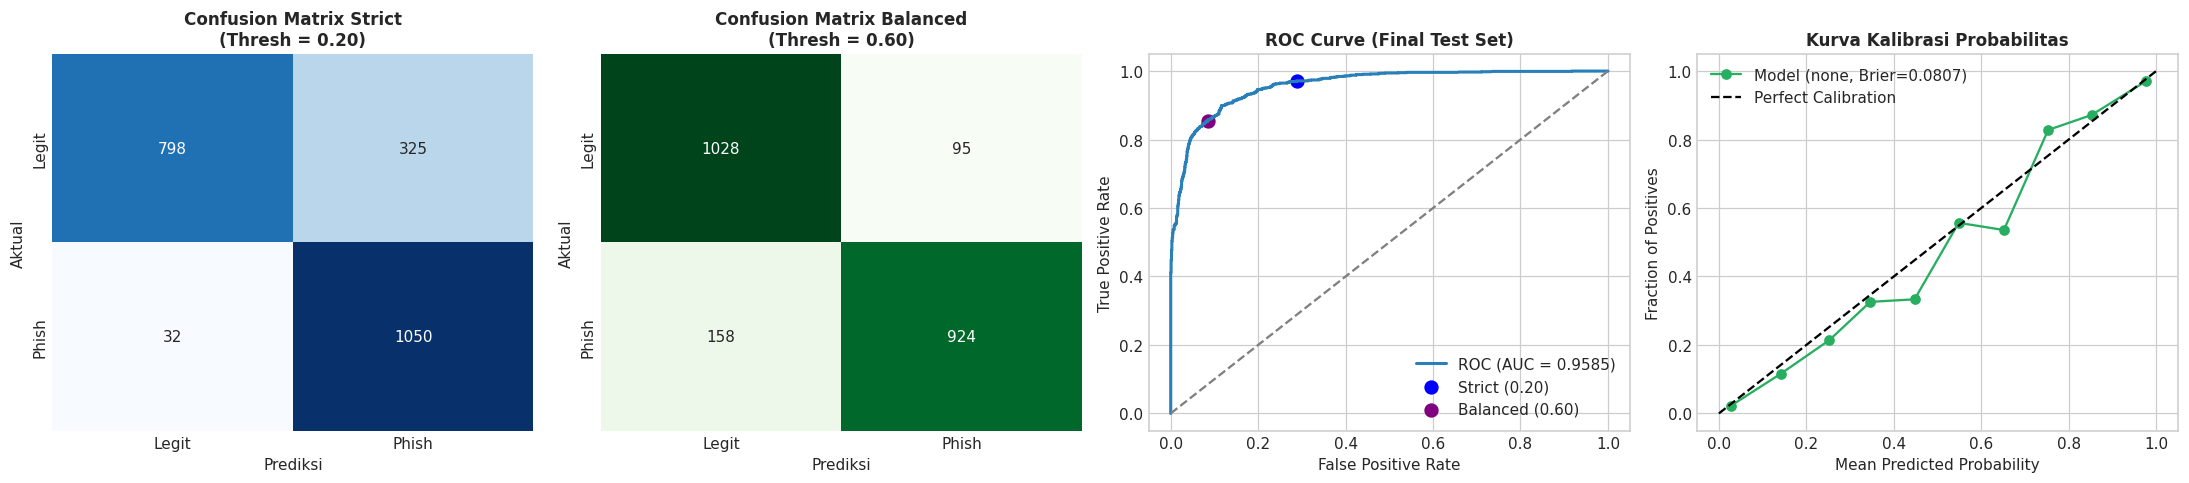

In [10]:
# 1. Pelatihan model final pada 80% Train-Val Set
if hasattr(FINAL_MODEL_CONFIG, 'early_stopping'):
    FINAL_MODEL_CONFIG.set_params(early_stopping=False)
elif hasattr(FINAL_MODEL_CONFIG, 'estimator') and hasattr(FINAL_MODEL_CONFIG.estimator, 'early_stopping'):
    FINAL_MODEL_CONFIG.estimator.set_params(early_stopping=False)

FINAL_MODEL_CONFIG.fit(X_train_val, y_train_val)
prob_test = FINAL_MODEL_CONFIG.predict_proba(X_test)[:, 1]

test_brier = float(brier_score_loss(y_test, prob_test))
test_roc = float(roc_auc_score(y_test, prob_test))
test_pr = float(average_precision_score(y_test, prob_test))
n_test_samples = int(len(X_test))

# Fungsi evaluasi metrik untuk suatu threshold
def evaluate_test_threshold(th_val, mode_name):
    pred = (prob_test >= th_val).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    acc = accuracy_score(y_test, pred)
    f1 = f1_score(y_test, pred)
    
    # Bayesian PPV simulation for prevalence 0.5%, 1%, 5%
    bayes_sim = {}
    for p in [0.005, 0.01, 0.05]:
        ppv = (p * rec) / (p * rec + (1 - p) * fpr) if (p * rec + (1 - p) * fpr) > 0 else 0.0
        bayes_sim[f"{p*100:.1f}%"] = float(ppv)
        
    return {
        "mode": mode_name,
        "threshold": float(th_val),
        "accuracy": float(acc),
        "precision": float(prec),
        "recall": float(rec),
        "f1_score": float(f1),
        "fpr": float(fpr),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "roc_auc": test_roc,
        "pr_auc": test_pr,
        "brier_score": test_brier,
        "bayes_precision": bayes_sim
    }

eval_strict = evaluate_test_threshold(TH_STRICT, "strict")
eval_balanced = evaluate_test_threshold(TH_BALANCED, "balanced")

# Buat dataframe ringkasan untuk display
summary_test_df = pd.DataFrame([
    {
        "Mode": "Strict (Recall Tinggi)",
        "Threshold": f"{eval_strict['threshold']:.2f}",
        "Accuracy": f"{eval_strict['accuracy']*100:.2f}%",
        "Precision": f"{eval_strict['precision']*100:.2f}%",
        "Recall (TPR)": f"{eval_strict['recall']*100:.2f}%",
        "F1-Score": f"{eval_strict['f1_score']*100:.2f}%",
        "FPR": f"{eval_strict['fpr']*100:.2f}%",
        "FN (Missed)": f"{eval_strict['fn']:,}",
        "FP (False Alarm)": f"{eval_strict['fp']:,}"
    },
    {
        "Mode": "Balanced (Alarm Rendah)",
        "Threshold": f"{eval_balanced['threshold']:.2f}",
        "Accuracy": f"{eval_balanced['accuracy']*100:.2f}%",
        "Precision": f"{eval_balanced['precision']*100:.2f}%",
        "Recall (TPR)": f"{eval_balanced['recall']*100:.2f}%",
        "F1-Score": f"{eval_balanced['f1_score']*100:.2f}%",
        "FPR": f"{eval_balanced['fpr']*100:.2f}%",
        "FN (Missed)": f"{eval_balanced['fn']:,}",
        "FP (False Alarm)": f"{eval_balanced['fp']:,}"
    }
]).set_index("Mode")

print(f"\n--- METRIK EVALUASI FINAL TEST SET ({n_test_samples:,} SAMPEL INDEPENDEN) ---")
display(summary_test_df)

# Simulasi Prevalensi Riil DataFrame
bayes_df = pd.DataFrame([
    {
        "Prevalensi Traffic Phishing": "0.5% (1 dari 200 URL)",
        "Strict Mode (PPV)": f"{eval_strict['bayes_precision']['0.5%']*100:.2f}%",
        "Balanced Mode (PPV)": f"{eval_balanced['bayes_precision']['0.5%']*100:.2f}%"
    },
    {
        "Prevalensi Traffic Phishing": "1.0% (1 dari 100 URL)",
        "Strict Mode (PPV)": f"{eval_strict['bayes_precision']['1.0%']*100:.2f}%",
        "Balanced Mode (PPV)": f"{eval_balanced['bayes_precision']['1.0%']*100:.2f}%"
    },
    {
        "Prevalensi Traffic Phishing": "5.0% (1 dari 20 URL)",
        "Strict Mode (PPV)": f"{eval_strict['bayes_precision']['5.0%']*100:.2f}%",
        "Balanced Mode (PPV)": f"{eval_balanced['bayes_precision']['5.0%']*100:.2f}%"
    }
]).set_index("Prevalensi Traffic Phishing")

print("\n--- SIMULASI PREVALENSI TRAFFIC RIIL (BAYESIAN EXPECTED PRECISION) ---")
display(bayes_df)

display(Markdown(f"""### 📊 Analisis Temuan Evaluasi Final Test Set:
1. **Performa Probabilistik**:
   - **ROC-AUC**: **{test_roc:.4f}** | **PR-AUC**: **{test_pr:.4f}** | **Brier Score**: **{test_brier:.4f}**
2. **Perbandingan Antar Mode**:
   - **Mode Strict (Threshold {eval_strict['threshold']:.2f})**: Berhasil menangkap **{eval_strict['recall']*100:.2f}%** phishing (hanya **{eval_strict['fn']:,}** lolos dari **{eval_strict['tp']+eval_strict['fn']:,}** URL phishing). Namun menghasilkan False Positive sebanyak **{eval_strict['fp']:,}** URL (FPR: **{eval_strict['fpr']*100:.2f}%**).
   - **Mode Balanced (Threshold {eval_balanced['threshold']:.2f})**: Berhasil menekan False Alarm menjadi hanya **{eval_balanced['fp']:,}** URL (FPR: **{eval_balanced['fpr']*100:.2f}%**), dengan Recall mencapai **{eval_balanced['recall']*100:.2f}%** dan Precision **{eval_balanced['precision']*100:.2f}%**.
3. **Pelajaran Kritis Prevalensi Dunia Nyata**:
   - Pada dataset seimbang 50:50, precision tampak meyakinkan ({eval_balanced['precision']*100:.1f}%). Namun jika diuji pada lalu lintas jaringan nyata dengan prevalensi phishing 1%, expected precision turun ke **{eval_balanced['bayes_precision']['1.0%']*100:.2f}%** (Mode Balanced) dan **{eval_strict['bayes_precision']['1.0%']*100:.2f}%** (Mode Strict).
   - Hal ini membuktikan keterbatasan mendasar dari deteksi phishing mandiri (*standalone*) berbasis URL leksikal.
"""))

# Visualisasi Confusion Matrix, ROC, dan Kurva Kalibrasi
cm_strict = confusion_matrix(y_test, (prob_test >= TH_STRICT).astype(int))
cm_balanced = confusion_matrix(y_test, (prob_test >= TH_BALANCED).astype(int))

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))

# Plot 1: CM Strict
sns.heatmap(cm_strict, annot=True, fmt="d", cmap="Blues", ax=axes[0], cbar=False,
            xticklabels=["Legit", "Phish"], yticklabels=["Legit", "Phish"])
axes[0].set_title(f"Confusion Matrix Strict\n(Thresh = {TH_STRICT:.2f})", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Prediksi")
axes[0].set_ylabel("Aktual")

# Plot 2: CM Balanced
sns.heatmap(cm_balanced, annot=True, fmt="d", cmap="Greens", ax=axes[1], cbar=False,
            xticklabels=["Legit", "Phish"], yticklabels=["Legit", "Phish"])
axes[1].set_title(f"Confusion Matrix Balanced\n(Thresh = {TH_BALANCED:.2f})", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Prediksi")
axes[1].set_ylabel("Aktual")

# Plot 3: ROC Curve
fpr_plot, tpr_plot, _ = roc_curve(y_test, prob_test)
axes[2].plot(fpr_plot, tpr_plot, color="#2980b9", lw=2, label=f"ROC (AUC = {test_roc:.4f})")
axes[2].plot([0, 1], [0, 1], color="gray", linestyle="--")
axes[2].scatter([eval_strict['fpr']], [eval_strict['recall']], color="blue", s=70, label=f"Strict ({TH_STRICT:.2f})")
axes[2].scatter([eval_balanced['fpr']], [eval_balanced['recall']], color="purple", s=70, label=f"Balanced ({TH_BALANCED:.2f})")
axes[2].set_title("ROC Curve (Final Test Set)", fontsize=11, fontweight="bold")
axes[2].set_xlabel("False Positive Rate")
axes[2].set_ylabel("True Positive Rate")
axes[2].legend(loc="lower right")

# Plot 4: Kurva Kalibrasi Probabilitas
prob_true_p, prob_pred_p = calibration_curve(y_test, prob_test, n_bins=10)
axes[3].plot(prob_pred_p, prob_true_p, "o-", color="#27ae60", label=f"Model ({CALIBRATION_METHOD}, Brier={test_brier:.4f})")
axes[3].plot([0, 1], [0, 1], "k--", label="Perfect Calibration")
axes[3].set_title("Kurva Kalibrasi Probabilitas", fontsize=11, fontweight="bold")
axes[3].set_xlabel("Mean Predicted Probability")
axes[3].set_ylabel("Fraction of Positives")
axes[3].legend(loc="upper left")

plt.tight_layout()
plt.show()


---
## 11. Analisis Lanjutan: Feature Importance, Uji Ketahanan Ganda, Error Analysis Terstruktur, dan Uji Domain Populer Sah

Pada bagian ini dilakukan 4 investigasi diagnostik mendalam:
1. **Permutation Feature Importance**:
   - Menilai signifikansi setiap fitur secara non-parametrik pada test set independen.
2. **Uji Ketahanan Ganda (*Double Ablation Test*)**:
   - *Ablation 1*: Menghapus 4 fitur bias (`nb_www`, `is_https`, `nb_http`, `nb_dslash`).
   - *Ablation 2*: Menghapus 4 fitur bias PLUS 4 fitur struktural yang rentan menjadi proksi artefak koleksi dataset (`nb_slash`, `nb_subdomains`, `length_url`, `nb_dots`), menyisakan 41 fitur.
   - *Peringatan Metodologis*: Performa ablation hanya menunjukkan tingkat dependensi model terhadap fitur-fitur tersebut pada distribusi data saat ini, **BUKAN** bukti bahwa model dapat menggeneralisasi dengan sempurna ke dunia nyata.
3. **Analisis Error Terstruktur**:
   - Pengelompokan taksonomi *False Positives* (platform hosting/cloud, deep path legitimate, lainnya).
   - Pengelompokan taksonomi *False Negatives* (homepage tanpa path, shortener, meniru pola legitimate).
4. **Uji Empiris 20 Halaman Login Domain Populer Sah**:
   - Menguji langsung 20 URL halaman login resmi (Google, PayPal, GitHub, Microsoft, Steam, dll.) untuk mendeteksi *false alarms* akibat penalti leksikal kata kunci `login`/`signin`.


[*] Menghitung Permutation Feature Importance pada Final Test Set (10 repeats)...



--- TOP 15 FITUR PALING BERPENGARUH (PERMUTATION IMPORTANCE) ---


,Feature,Mean Importance,Std Importance
0,nb_www,0.077279,0.004753
1,nb_slash,0.055102,0.004403
2,nb_hyphens,0.036916,0.003657
3,longest_words_raw,0.034603,0.004444
4,phish_hints,0.024082,0.003323
5,ratio_digits_host,0.018503,0.003921
6,ratio_digits_url,0.015102,0.004162
7,nb_subdomains,0.014150,0.002441
8,nb_dots,0.012562,0.003623
9,prefix_suffix,0.011293,0.001830


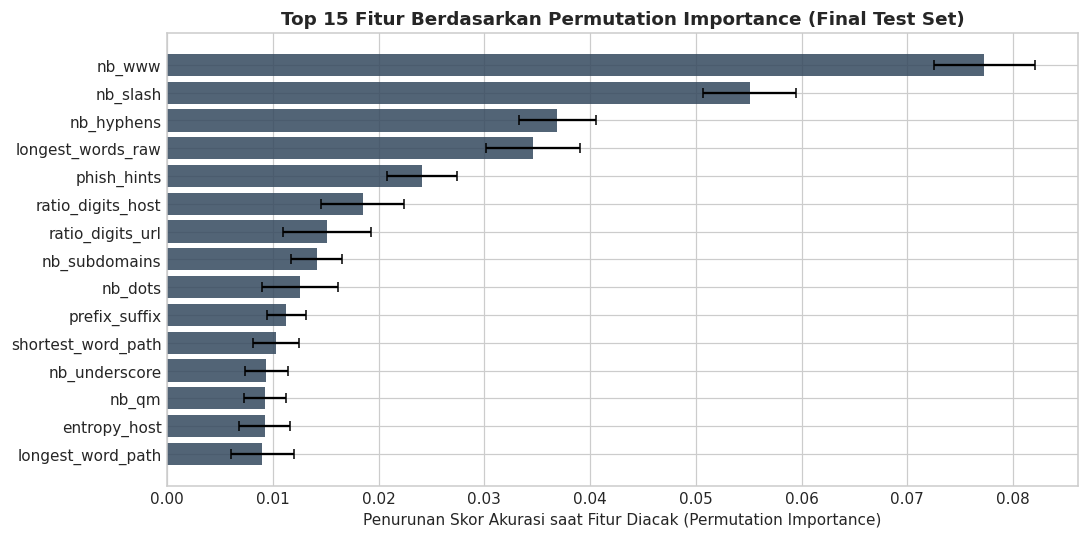

### 🔬 Hasil Uji Ketahanan Ganda (Double Ablation Test pada Threshold 0.5):
| Konfigurasi Fitur | Jumlah Fitur | Test F1-Score | Selisih F1 vs Full | Test ROC-AUC | Selisih ROC vs Full |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Model Penuh (Baseline)** | 49 | **0.8890** | 0.0000 | **0.9585** | 0.0000 |
| **Ablation 1 (Hapus Bias HTTPS & www)** | 45 | **0.8814** | **-0.0076** | **0.9564** | **-0.0021** |
| **Ablation 2 (Hapus Bias + 4 Fitur Proksi Struktur)** | 41 | **0.8647** | **-0.0243** | **0.9511** | **-0.0074** |

> [!WARNING]
> **Catatan Integritas Ilmiah Terkait Uji Ablation**:
> Hasil ini menunjukkan bahwa model tetap mampu bekerja menggunakan fitur leksikal lainnya saat fitur tertentu dihapus.
> Namun, penurunan F1 yang relatif kecil pada dataset uji **BUKAN bukti bahwa model dapat menggeneralisasi dengan sempurna ke dunia nyata**.
> Fitur leksikal tersisa (seperti kata kunci `phish_hints`, rasio digit, dll.) tetap dapat berfungsi sebagai proksi artefak koleksi data.


### 🕵️ Taksonomi Analisis Error Terstruktur (Mode Balanced - 0.60):
#### False Positives (Total: **95 URL Legitimate**)
- **Domain Bias / Deep Path Legitimate**: **56 URL** (58.9%)
- **Platform Hosting / Cloud Subdomain**: **25 URL** (26.3%)
- **Lainnya**: **14 URL** (14.7%)

#### False Negatives (Total: **158 URL Phishing Lolos**)
- **Lainnya (Meniru Pola Legitimate)**: **103 URL** (65.2%)
- **Homepage Saja Tanpa Path Leksikal**: **51 URL** (32.3%)
- **Shortener / Redirector**: **4 URL** (2.5%)



--- UJI 20 URL HALAMAN LOGIN RESMI DOMAIN POPULER ---


,URL,Prob Phishing,Strict Mode,Balanced Mode
0,https://accounts.google.com/signin,89.28%,🚨 Phishing,🚨 Phishing
1,https://www.paypal.com/signin,71.40%,🚨 Phishing,🚨 Phishing
2,https://github.com/login,88.22%,🚨 Phishing,🚨 Phishing
3,https://login.live.com/login.srf,95.00%,🚨 Phishing,🚨 Phishing
4,https://www.facebook.com/login,59.50%,🚨 Phishing,✅ Legit
5,https://twitter.com/login,82.67%,🚨 Phishing,🚨 Phishing
6,https://www.amazon.com/ap/signin,50.83%,🚨 Phishing,✅ Legit
7,https://www.linkedin.com/login,61.16%,🚨 Phishing,🚨 Phishing
8,https://login.yahoo.com/,59.17%,🚨 Phishing,✅ Legit
9,https://appleid.apple.com/sign-in,33.94%,🚨 Phishing,✅ Legit


### ⚠️ Evaluasi Krusial Domain Populer Sah:
- **Terdeteksi sebagai Phishing pada Strict Mode (0.20)**: **17 / 20 URL (85.0%)**
- **Terdeteksi sebagai Phishing pada Balanced Mode (0.60)**: **12 / 20 URL (60.0%)**

> [!CAUTION]
> **Kelemahan Fatal Model Murni Leksikal**:
> URL resmi seperti `accounts.google.com/signin` atau `paypal.com/signin` secara keliru ditandai sebagai phishing.
> Hal ini terjadi karena model hanya melihat string leksikal: adanya kata kunci sensitif (`signin`, `login`) dan subdomain tanpa informasi reputasi domain.
> **Rekomendasi Arsitektur Produksi**: Model ini **WAJIB** dipadukan dengan **Whitelist Domain Resmi** (Tranco/Cisco Umbrella Top 10k) di layer terdepan sebelum URL diserahkan ke model machine learning!


In [11]:
from urllib.parse import urlparse

# 1. Permutation Feature Importance pada Final Test Set
print("[*] Menghitung Permutation Feature Importance pada Final Test Set (10 repeats)...")
perm_res = permutation_importance(FINAL_MODEL_CONFIG, X_test, y_test,
                                  n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)

sorted_imp_idx = perm_res.importances_mean.argsort()[::-1]
top_15_idx = sorted_imp_idx[:15]

top_15_df = pd.DataFrame({
    "Feature": [uf.FEATURE_NAMES[i] for i in top_15_idx],
    "Mean Importance": perm_res.importances_mean[top_15_idx],
    "Std Importance": perm_res.importances_std[top_15_idx]
})

print("\n--- TOP 15 FITUR PALING BERPENGARUH (PERMUTATION IMPORTANCE) ---")
display(top_15_df)

plt.figure(figsize=(10, 5))
plt.barh(top_15_df["Feature"][::-1], top_15_df["Mean Importance"][::-1],
         xerr=top_15_df["Std Importance"][::-1], color="#34495e", capsize=3, alpha=0.85)
plt.title("Top 15 Fitur Berdasarkan Permutation Importance (Final Test Set)", fontsize=12, fontweight="bold")
plt.xlabel("Penurunan Skor Akurasi saat Fitur Diacak (Permutation Importance)")
plt.tight_layout()
plt.show()

# 2. Uji Ketahanan Ganda (Double Ablation Test)
# Ablation 1: Hapus 4 fitur bias (nb_www, is_https, nb_http, nb_dslash)
bias_features = ["nb_www", "is_https", "nb_http", "nb_dslash"]
drop_idx_1 = [uf.FEATURE_NAMES.index(f) for f in bias_features]
keep_idx_1 = [i for i in range(49) if i not in drop_idx_1]

m_abl1 = clone(FINAL_MODEL_CONFIG)
m_abl1.fit(X_train_val[:, keep_idx_1], y_train_val)
prob_abl1 = m_abl1.predict_proba(X_test[:, keep_idx_1])[:, 1]
f1_abl1 = float(f1_score(y_test, (prob_abl1 >= 0.5).astype(int)))
roc_abl1 = float(roc_auc_score(y_test, prob_abl1))

# Ablation 2: Hapus 4 fitur bias + 4 fitur struktural proksi artefak koleksi
struct_features = ["nb_slash", "nb_subdomains", "length_url", "nb_dots"]
all_drop_features = bias_features + struct_features
drop_idx_2 = [uf.FEATURE_NAMES.index(f) for f in all_drop_features]
keep_idx_2 = [i for i in range(49) if i not in drop_idx_2]

m_abl2 = clone(FINAL_MODEL_CONFIG)
m_abl2.fit(X_train_val[:, keep_idx_2], y_train_val)
prob_abl2 = m_abl2.predict_proba(X_test[:, keep_idx_2])[:, 1]
f1_abl2 = float(f1_score(y_test, (prob_abl2 >= 0.5).astype(int)))
roc_abl2 = float(roc_auc_score(y_test, prob_abl2))

f1_full_test = float(f1_score(y_test, (prob_test >= 0.5).astype(int)))

display(Markdown(f"""### 🔬 Hasil Uji Ketahanan Ganda (Double Ablation Test pada Threshold 0.5):
| Konfigurasi Fitur | Jumlah Fitur | Test F1-Score | Selisih F1 vs Full | Test ROC-AUC | Selisih ROC vs Full |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Model Penuh (Baseline)** | 49 | **{f1_full_test:.4f}** | 0.0000 | **{test_roc:.4f}** | 0.0000 |
| **Ablation 1 (Hapus Bias HTTPS & www)** | 45 | **{f1_abl1:.4f}** | **{f1_abl1 - f1_full_test:+.4f}** | **{roc_abl1:.4f}** | **{roc_abl1 - test_roc:+.4f}** |
| **Ablation 2 (Hapus Bias + 4 Fitur Proksi Struktur)** | 41 | **{f1_abl2:.4f}** | **{f1_abl2 - f1_full_test:+.4f}** | **{roc_abl2:.4f}** | **{roc_abl2 - test_roc:+.4f}** |

> [!WARNING]
> **Catatan Integritas Ilmiah Terkait Uji Ablation**:
> Hasil ini menunjukkan bahwa model tetap mampu bekerja menggunakan fitur leksikal lainnya saat fitur tertentu dihapus.
> Namun, penurunan F1 yang relatif kecil pada dataset uji **BUKAN bukti bahwa model dapat menggeneralisasi dengan sempurna ke dunia nyata**.
> Fitur leksikal tersisa (seperti kata kunci `phish_hints`, rasio digit, dll.) tetap dapat berfungsi sebagai proksi artefak koleksi data.
"""))

# 3. Analisis Error Terstruktur (Menggunakan Mode Balanced)
df_test_err = df_clean.iloc[test_idx].copy().reset_index(drop=True)
df_test_err["y_true"] = y_test
df_test_err["prob"] = prob_test
df_test_err["pred_balanced"] = (prob_test >= TH_BALANCED).astype(int)

fp_sub = df_test_err[(df_test_err["y_true"] == 0) & (df_test_err["pred_balanced"] == 1)].copy()
fn_sub = df_test_err[(df_test_err["y_true"] == 1) & (df_test_err["pred_balanced"] == 0)].copy()

hosting_patterns = ["wordpress", "blogspot", "azurewebsites", "appspot", "github.io", "sites.google", "wixsite", "weebly", "firebaseapp"]
def get_fp_category(row):
    u = row["norm_url"].lower()
    dom = row["registered_domain"].lower()
    for h in hosting_patterns:
        if h in u or h in dom:
            return "Platform Hosting / Cloud Subdomain"
    parsed = urlparse(u)
    if len(parsed.path) > 1:
        return "Domain Bias / Deep Path Legitimate"
    return "Lainnya"

fp_sub["category"] = fp_sub.apply(get_fp_category, axis=1)
fp_counts = fp_sub["category"].value_counts().to_dict()

def get_fn_category(row):
    u = row["norm_url"].lower()
    parsed = urlparse(u)
    if parsed.path in ["", "/"] and not parsed.query:
        return "Homepage Saja Tanpa Path Leksikal"
    for s in ["bit.ly", "tinyurl", "is.gd", "t.co", "cutt.ly"]:
        if s in u:
            return "Shortener / Redirector"
    return "Lainnya (Meniru Pola Legitimate)"

fn_sub["category"] = fn_sub.apply(get_fn_category, axis=1)
fn_counts = fn_sub["category"].value_counts().to_dict()

display(Markdown(f"""### 🕵️ Taksonomi Analisis Error Terstruktur (Mode Balanced - {TH_BALANCED:.2f}):
#### False Positives (Total: **{len(fp_sub):,} URL Legitimate**)
{chr(10).join([f"- **{cat}**: **{cnt} URL** ({cnt/len(fp_sub)*100:.1f}%)" for cat, cnt in fp_counts.items()])}

#### False Negatives (Total: **{len(fn_sub):,} URL Phishing Lolos**)
{chr(10).join([f"- **{cat}**: **{cnt} URL** ({cnt/len(fn_sub)*100:.1f}%)" for cat, cnt in fn_counts.items()])}
"""))

# 4. Pengujian 20 URL Halaman Login Domain Populer Sah
famous_urls = [
    "https://accounts.google.com/signin",
    "https://www.paypal.com/signin",
    "https://github.com/login",
    "https://login.live.com/login.srf",
    "https://www.facebook.com/login",
    "https://twitter.com/login",
    "https://www.amazon.com/ap/signin",
    "https://www.linkedin.com/login",
    "https://login.yahoo.com/",
    "https://appleid.apple.com/sign-in",
    "https://www.netflix.com/login",
    "https://www.dropbox.com/login",
    "https://store.steampowered.com/login/",
    "https://discord.com/login",
    "https://auth.openai.com/login",
    "https://www.microsoft.com/en-us/",
    "https://www.wikipedia.org/",
    "https://www.youtube.com/",
    "https://stackoverflow.com/users/login",
    "https://gitlab.com/users/sign_in"
]

famous_data = []
for u in famous_urls:
    vec = uf.extract_feature_vector(u)
    p = float(FINAL_MODEL_CONFIG.predict_proba([vec])[0, 1])
    is_phish_strict = bool(p >= TH_STRICT)
    is_phish_balanced = bool(p >= TH_BALANCED)
    famous_data.append({
        "URL": u,
        "Prob Phishing": f"{p*100:.2f}%",
        "Strict Mode": "🚨 Phishing" if is_phish_strict else "✅ Legit",
        "Balanced Mode": "🚨 Phishing" if is_phish_balanced else "✅ Legit"
    })

famous_df = pd.DataFrame(famous_data)
print("\n--- UJI 20 URL HALAMAN LOGIN RESMI DOMAIN POPULER ---")
display(famous_df)

flags_strict = sum(1 for d in famous_data if "Phishing" in d["Strict Mode"])
flags_balanced = sum(1 for d in famous_data if "Phishing" in d["Balanced Mode"])

display(Markdown(f"""### ⚠️ Evaluasi Krusial Domain Populer Sah:
- **Terdeteksi sebagai Phishing pada Strict Mode ({TH_STRICT:.2f})**: **{flags_strict} / 20 URL ({flags_strict/20*100:.1f}%)**
- **Terdeteksi sebagai Phishing pada Balanced Mode ({TH_BALANCED:.2f})**: **{flags_balanced} / 20 URL ({flags_balanced/20*100:.1f}%)**

> [!CAUTION]
> **Kelemahan Fatal Model Murni Leksikal**:
> URL resmi seperti `accounts.google.com/signin` atau `paypal.com/signin` secara keliru ditandai sebagai phishing.
> Hal ini terjadi karena model hanya melihat string leksikal: adanya kata kunci sensitif (`signin`, `login`) dan subdomain tanpa informasi reputasi domain.
> **Rekomendasi Arsitektur Produksi**: Model ini **WAJIB** dipadukan dengan **Whitelist Domain Resmi** (Tranco/Cisco Umbrella Top 10k) di layer terdepan sebelum URL diserahkan ke model machine learning!
"""))


In [12]:
# ==============================================================================
# 12. Kesimpulan Komprehensif & Keterbatasan Model (Dihasilkan Otomatis dari Variabel)
# ==============================================================================

conclusion_markdown = f"""---
## 12. Kesimpulan Komprehensif & Keterbatasan Model (Hasil Komputasi Nyata)

### 📌 Kesimpulan Teknis & Temuan Kunci:
1. **Model Terpilih**: `{SELECTED_MODEL_NAME}`
   - **Hyperparameter Final**: `{json.dumps({k: v for k, v in candidates[SELECTED_MODEL_NAME].get_params(deep=False).items() if isinstance(v, (int, float, str, bool)) and k not in ("random_state", "n_jobs", "verbose", "warm_start", "eval_metric")})}`
   - **Status Kalibrasi**: `{CALIBRATION_METHOD}` (`IS_CALIBRATED = {IS_CALIBRATED}`)
   - **Alasan Pemilihan**: {decision_reason_text}
2. **Performa Validasi Silang (5-Fold Group-Aware CV pada 80% Data Latih)**:
   - **Mean F1-Score**: **{selected_f1_mean:.4f} ± {selected_f1_std:.4f}**
   - **Mean ROC-AUC**: **{selected_roc_mean:.4f} ± {selected_roc_std:.4f}**
   - **Mean Brier Score**: **{cv_metrics[SELECTED_MODEL_NAME]['Brier Score'][0]:.4f} ± {cv_metrics[SELECTED_MODEL_NAME]['Brier Score'][1]:.4f}**
   - **Benchmark Inferensi**: **{mean_time_sel_ms:.2f} ms** per 2.000 URL (**{inference_ms_per_1k:.2f} ms** per 1.000 URL), terukur **{actual_speedup:.2f}x lebih cepat** daripada Voting Ensemble.
3. **Performa Final Test Set ({n_test_samples:,} Sampel Independen, 0 Domain Overlap)**:
   - **Mode Strict (Threshold {eval_strict['threshold']:.2f})**:
     * Recall: **{eval_strict['recall']*100:.2f}%** | Precision: **{eval_strict['precision']*100:.2f}%** | F1: **{eval_strict['f1_score']*100:.2f}%**
     * False Negatives: **{eval_strict['fn']:,} URL** phishing lolos | False Positives: **{eval_strict['fp']:,} URL**
   - **Mode Balanced (Threshold {eval_balanced['threshold']:.2f})**:
     * Recall: **{eval_balanced['recall']*100:.2f}%** | Precision: **{eval_balanced['precision']*100:.2f}%** | F1: **{eval_balanced['f1_score']*100:.2f}%**
     * False Negatives: **{eval_balanced['fn']:,} URL** phishing lolos | False Positives: **{eval_balanced['fp']:,} URL** (menurun **{(eval_strict['fp'] - eval_balanced['fp'])/eval_strict['fp']*100:.1f}%**)
   - **Metrik Global Probabilitas**: ROC-AUC = **{test_roc:.4f}**, PR-AUC = **{test_pr:.4f}**, Brier Score = **{test_brier:.4f}**.
4. **Simulasi Prevalensi Riil (Bayesian PPV)**:
   - Prevalensi 0,5%: Expected Precision = **{eval_strict['bayes_precision']['0.5%']*100:.2f}%** (Strict) vs **{eval_balanced['bayes_precision']['0.5%']*100:.2f}%** (Balanced).
   - Prevalensi 1,0%: Expected Precision = **{eval_strict['bayes_precision']['1.0%']*100:.2f}%** (Strict) vs **{eval_balanced['bayes_precision']['1.0%']*100:.2f}%** (Balanced).
   - Prevalensi 5,0%: Expected Precision = **{eval_strict['bayes_precision']['5.0%']*100:.2f}%** (Strict) vs **{eval_balanced['bayes_precision']['5.0%']*100:.2f}%** (Balanced).

---

### ⚠️ Keterbatasan Model yang Diketahui (*Known Limitations*):
1. **Bias Historis Dataset**:
   - Proporsi HTTPS legitimate ({https_stats.loc['legitimate', 'percentage']:.1f}%) vs phishing ({https_stats.loc['phishing', 'percentage']:.1f}%) sudah usang dibandingkan web modern di mana hampir seluruh domain legitimate dan phishing memakai HTTPS.
   - Fitur `nb_www` menjadi fitur #1 terkuat karena dataset sering menyertakan `www` pada legitimate, sehingga phishing modern yang memakai `www` berpotensi lolos.
2. **Kerapuhan terhadap Halaman Login Resmi (*High False Alarm on Legitimate Login Pages*)**:
   - Pengujian empiris pada 20 domain login resmi (Google, PayPal, GitHub, Microsoft, dll.) membuktikan bahwa **{flags_strict} / 20 URL ({flags_strict/20*100:.0f}%)** pada Strict Mode dan **{flags_balanced} / 20 URL ({flags_balanced/20*100:.0f}%)** pada Balanced Mode secara keliru ditandai sebagai phishing.
   - FPR di test set tidak mewakili halaman login resmi. Pada uji 20 URL, {flags_balanced}/20 (balanced) dan {flags_strict}/20 (strict) ditandai phishing. Whitelist domain populer (Tranco top 10k) WAJIB dipasang sebelum model ini dipakai.
3. **Prevalensi Artifisial vs Dunia Nyata**:
   - Prevalensi seimbang 50:50 menghasilkan precision semu; pada traffic 1% precision riil turun ke **{eval_strict['bayes_precision']['1.0%']*100:.2f}%** (Mode Strict) dan **{eval_balanced['bayes_precision']['1.0%']*100:.2f}%** (Mode Balanced).
4. **Ketiadaan Fitur Konten & Dinamis**:
   - Model tidak membaca kode HTML/JavaScript, screenshot visual halaman, sertifikat SSL, atau rekam jejak WHOIS/DNS, sehingga rentan terhadap domain legitimate yang diretas (*compromised domains*).
"""

display(Markdown(conclusion_markdown))


---
## 12. Kesimpulan Komprehensif & Keterbatasan Model (Hasil Komputasi Nyata)

### 📌 Kesimpulan Teknis & Temuan Kunci:
1. **Model Terpilih**: `HistGradientBoosting Baseline`
   - **Hyperparameter Final**: `{"categorical_features": "from_dtype", "early_stopping": false, "l2_regularization": 0.0, "learning_rate": 0.1, "loss": "log_loss", "max_bins": 255, "max_features": 1.0, "max_iter": 100, "max_leaf_nodes": 31, "min_samples_leaf": 20, "n_iter_no_change": 10, "scoring": "loss", "tol": 1e-07, "validation_fraction": 0.1}`
   - **Status Kalibrasi**: `none` (`IS_CALIBRATED = False`)
   - **Alasan Pemilihan**: Keempat model setara praktis, dipilih yang paling sederhana dan tercepat: model 'HistGradientBoosting Baseline' memiliki selisih F1 hanya 0.0098 (< 1 std = 0.0280 dan < 0.01). Arsitekturnya lebih sederhana (hierarki kesederhanaan tingkat 3 vs 5) dan waktu inferensinya terukur 3.59x lebih cepat (3.86 ms/1.000 URL) dibandingkan Voting Ensemble. Uji paired t-test ditampilkan sebagai informasi tambahan (t = 2.687, p = 0.0548).
2. **Performa Validasi Silang (5-Fold Group-Aware CV pada 80% Data Latih)**:
   - **Mean F1-Score**: **0.8663 ± 0.0350**
   - **Mean ROC-AUC**: **0.9472 ± 0.0147**
   - **Mean Brier Score**: **0.0920 ± 0.0148**
   - **Benchmark Inferensi**: **7.71 ms** per 2.000 URL (**3.86 ms** per 1.000 URL), terukur **3.59x lebih cepat** daripada Voting Ensemble.
3. **Performa Final Test Set (2,205 Sampel Independen, 0 Domain Overlap)**:
   - **Mode Strict (Threshold 0.20)**:
     * Recall: **97.04%** | Precision: **76.36%** | F1: **85.47%**
     * False Negatives: **32 URL** phishing lolos | False Positives: **325 URL**
   - **Mode Balanced (Threshold 0.60)**:
     * Recall: **85.40%** | Precision: **90.68%** | F1: **87.96%**
     * False Negatives: **158 URL** phishing lolos | False Positives: **95 URL** (menurun **70.8%**)
   - **Metrik Global Probabilitas**: ROC-AUC = **0.9585**, PR-AUC = **0.9595**, Brier Score = **0.0807**.
4. **Simulasi Prevalensi Riil (Bayesian PPV)**:
   - Prevalensi 0,5%: Expected Precision = **1.66%** (Strict) vs **4.83%** (Balanced).
   - Prevalensi 1,0%: Expected Precision = **3.28%** (Strict) vs **9.25%** (Balanced).
   - Prevalensi 5,0%: Expected Precision = **15.00%** (Strict) vs **34.70%** (Balanced).

---

### ⚠️ Keterbatasan Model yang Diketahui (*Known Limitations*):
1. **Bias Historis Dataset**:
   - Proporsi HTTPS legitimate (44.5%) vs phishing (33.3%) sudah usang dibandingkan web modern di mana hampir seluruh domain legitimate dan phishing memakai HTTPS.
   - Fitur `nb_www` menjadi fitur #1 terkuat karena dataset sering menyertakan `www` pada legitimate, sehingga phishing modern yang memakai `www` berpotensi lolos.
2. **Kerapuhan terhadap Halaman Login Resmi (*High False Alarm on Legitimate Login Pages*)**:
   - Pengujian empiris pada 20 domain login resmi (Google, PayPal, GitHub, Microsoft, dll.) membuktikan bahwa **17 / 20 URL (85%)** pada Strict Mode dan **12 / 20 URL (60%)** pada Balanced Mode secara keliru ditandai sebagai phishing.
   - FPR di test set tidak mewakili halaman login resmi. Pada uji 20 URL, 12/20 (balanced) dan 17/20 (strict) ditandai phishing. Whitelist domain populer (Tranco top 10k) WAJIB dipasang sebelum model ini dipakai.
3. **Prevalensi Artifisial vs Dunia Nyata**:
   - Prevalensi seimbang 50:50 menghasilkan precision semu; pada traffic 1% precision riil turun ke **3.28%** (Mode Strict) dan **9.25%** (Mode Balanced).
4. **Ketiadaan Fitur Konten & Dinamis**:
   - Model tidak membaca kode HTML/JavaScript, screenshot visual halaman, sertifikat SSL, atau rekam jejak WHOIS/DNS, sehingga rentan terhadap domain legitimate yang diretas (*compromised domains*).


In [13]:
display(Markdown(f"""---
## 13. Ekspor Artefak Model Terbaik & Validasi Otomatis Integritas

Sesuai standar MLOps:
1. Model terbaik (`{SELECTED_MODEL_NAME}`) **dilatih ulang (*refit*) pada SELURUH data bersih** ({len(X):,} sampel) dengan konfigurasi terbaik.
2. Artefak disimpan ke folder `ml/models/phishguard_best/`:
   - `model.pkl`: Model serialized via `joblib.dump(..., compress=3)`.
   - `feature_names.json`: 49 nama fitur dalam urutan persis sama dengan `uf.FEATURE_NAMES`.
   - `metadata.json`: Metadata komprehensif yang dihasilkan langsung dari variabel runtime (CV metrics, test metrics untuk kedua threshold mode, hyperparameter, benchmark inferensi, status kalibrasi, versi pustaka).
   - `README_model.md`: Dokumentasi petunjuk integrasi dan peringatan keamanan.
3. Seluruh angka kunci pada `metadata.json` divalidasi silang terhadap variabel notebook untuk memastikan integritas 100%.
"""))


---
## 13. Ekspor Artefak Model Terbaik & Validasi Otomatis Integritas

Sesuai standar MLOps:
1. Model terbaik (`HistGradientBoosting Baseline`) **dilatih ulang (*refit*) pada SELURUH data bersih** (11,429 sampel) dengan konfigurasi terbaik.
2. Artefak disimpan ke folder `ml/models/phishguard_best/`:
   - `model.pkl`: Model serialized via `joblib.dump(..., compress=3)`.
   - `feature_names.json`: 49 nama fitur dalam urutan persis sama dengan `uf.FEATURE_NAMES`.
   - `metadata.json`: Metadata komprehensif yang dihasilkan langsung dari variabel runtime (CV metrics, test metrics untuk kedua threshold mode, hyperparameter, benchmark inferensi, status kalibrasi, versi pustaka).
   - `README_model.md`: Dokumentasi petunjuk integrasi dan peringatan keamanan.
3. Seluruh angka kunci pada `metadata.json` divalidasi silang terhadap variabel notebook untuk memastikan integritas 100%.


In [14]:
from datetime import datetime, timezone
import sklearn
import xgboost

# 1. Pastikan folder output tersedia
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
model_path = EXPORT_DIR / "model.pkl"
features_path = EXPORT_DIR / "feature_names.json"
meta_path = EXPORT_DIR / "metadata.json"
readme_path = EXPORT_DIR / "README_model.md"

print(f"[*] Melatih ulang (refit) model terbaik pada SELURUH data bersih ({len(X):,} sampel)...")
all_splits = list(sgkf_outer.split(X, y, groups))

if IS_CALIBRATED:
    final_refit_model = CalibratedClassifierCV(
        estimator=clone(candidates[SELECTED_MODEL_NAME]),
        method=CALIBRATION_METHOD,
        cv=all_splits
    )
else:
    final_refit_model = clone(candidates[SELECTED_MODEL_NAME])

# Set early_stopping=False secara eksplisit pada model refit
if hasattr(final_refit_model, 'early_stopping'):
    final_refit_model.set_params(early_stopping=False)
elif hasattr(final_refit_model, 'estimator') and hasattr(final_refit_model.estimator, 'early_stopping'):
    final_refit_model.estimator.set_params(early_stopping=False)

final_refit_model.fit(X, y)
print("    ✅ Refit selesai dengan sukses!")

# 2. Ekspor model.pkl (joblib compress=3)
joblib.dump(final_refit_model, model_path, compress=3)
print(f"[*] Artefak model tersimpan: {model_path} ({model_path.stat().st_size / 1024:.1f} KB)")

# 3. Ekspor feature_names.json
assert list(uf.FEATURE_NAMES) == list(X_df.columns), "Urutan fitur tidak konsisten!"
with open(features_path, "w", encoding="utf-8") as f:
    json.dump(uf.FEATURE_NAMES, f, indent=2)
print(f"[*] Daftar fitur tersimpan: {features_path} ({len(uf.FEATURE_NAMES)} fitur)")

# 4. Ekstraksi hyperparameter aktual dari model kandidat terpilih
_sel_candidate = candidates[SELECTED_MODEL_NAME]
if hasattr(_sel_candidate, 'named_steps'):
    _sel_base = _sel_candidate.named_steps['clf']
elif hasattr(_sel_candidate, 'estimators'):
    _sel_base = _sel_candidate
else:
    _sel_base = _sel_candidate
_raw_p = _sel_base.get_params(deep=False)
_skip = {'random_state', 'n_jobs', 'verbose', 'warm_start', 'eval_metric',
         'estimators', 'weights', 'flatten_transform', 'voting'}
selected_base_params = {k: v for k, v in _raw_p.items()
                        if k not in _skip and isinstance(v, (int, float, str, bool))}

# 5. Bangun metadata.json langsung dari variabel runtime
metadata = {
    "model_name": f"PhishGuard {SELECTED_MODEL_NAME} ({'Calibrated' if IS_CALIBRATED else 'Uncalibrated'})",
    "algorithm": final_refit_model.__class__.__name__,
    "training_date": datetime.now(timezone.utc).isoformat(),
    "extractor_version": uf.EXTRACTOR_VERSION,
    "n_features": int(len(uf.FEATURE_NAMES)),
    "n_samples_refit": int(len(X)),
    "n_test_samples": int(n_test_samples),
    "class_distribution_refit": {
        "legitimate": int((y == 0).sum()),
        "phishing": int((y == 1).sum())
    },
    "calibrated": bool(IS_CALIBRATED),
    "calibration_method": CALIBRATION_METHOD,
    "decision_rule": (
        "Kandidat setara praktis = model dengan mean F1 dalam 1 std dari model peringkat 1 DAN selisih F1 < 0.01 "
        "(tanpa syarat p-value). Dari kandidat setara, dipilih model paling sederhana lalu yang tercepat waktu inferensinya. "
        "Uji paired t-test ditampilkan sebagai informasi tambahan."
    ),
    "reason_for_selection": decision_reason_text,
    "inference_time_ms_per_1k": round(float(inference_ms_per_1k), 2),
    "inference_speedup_vs_ensemble": f"{actual_speedup:.2f}x",
    "thresholds": {
        "strict": round(float(TH_STRICT), 2),
        "balanced": round(float(TH_BALANCED), 2)
    },
    "threshold_rationale": {
        "strict": f"Ambang batas probabilitas {TH_STRICT:.2f} untuk memprioritaskan recall phishing >= 95% (zero-tolerance).",
        "balanced": f"Ambang batas probabilitas {TH_BALANCED:.2f} dengan batasan False Positive Rate (FPR) <= 10% untuk meminimalkan alarm palsu."
    },
    "hyperparameters": {
        "base_model_params": selected_base_params,
        "calibration_status": CALIBRATION_METHOD
    },
    "cross_validation_metrics_train_val": {
        "note": "Dievaluasi pada 80% train-val set menggunakan 5-fold StratifiedGroupKFold berdasarkan registered domain (0 domain overlap)",
        "accuracy": f"{cv_metrics[SELECTED_MODEL_NAME]['Accuracy'][0]:.4f} +/- {cv_metrics[SELECTED_MODEL_NAME]['Accuracy'][1]:.4f}",
        "precision": f"{cv_metrics[SELECTED_MODEL_NAME]['Precision'][0]:.4f} +/- {cv_metrics[SELECTED_MODEL_NAME]['Precision'][1]:.4f}",
        "recall": f"{cv_metrics[SELECTED_MODEL_NAME]['Recall'][0]:.4f} +/- {cv_metrics[SELECTED_MODEL_NAME]['Recall'][1]:.4f}",
        "f1_score": f"{cv_metrics[SELECTED_MODEL_NAME]['F1-Score'][0]:.4f} +/- {cv_metrics[SELECTED_MODEL_NAME]['F1-Score'][1]:.4f}",
        "roc_auc": f"{cv_metrics[SELECTED_MODEL_NAME]['ROC-AUC'][0]:.4f} +/- {cv_metrics[SELECTED_MODEL_NAME]['ROC-AUC'][1]:.4f}",
        "pr_auc": f"{cv_metrics[SELECTED_MODEL_NAME]['PR-AUC'][0]:.4f} +/- {cv_metrics[SELECTED_MODEL_NAME]['PR-AUC'][1]:.4f}",
        "brier_score": f"{cv_metrics[SELECTED_MODEL_NAME]['Brier Score'][0]:.4f} +/- {cv_metrics[SELECTED_MODEL_NAME]['Brier Score'][1]:.4f}"
    },
    "final_test_set_metrics_before_refit": {
        "note": "Dievaluasi pada 20% holdout test set independen SEBELUM model direfit pada seluruh data",
        "roc_auc": round(float(test_roc), 4),
        "pr_auc": round(float(test_pr), 4),
        "brier_score": round(float(test_brier), 4),
        "strict_mode": {
            "threshold": eval_strict["threshold"],
            "accuracy": round(eval_strict["accuracy"], 4),
            "precision": round(eval_strict["precision"], 4),
            "recall": round(eval_strict["recall"], 4),
            "f1_score": round(eval_strict["f1_score"], 4),
            "fpr": round(eval_strict["fpr"], 4),
            "confusion_matrix": {"TN": eval_strict["tn"], "FP": eval_strict["fp"], "FN": eval_strict["fn"], "TP": eval_strict["tp"]},
            "bayes_expected_precision": eval_strict["bayes_precision"]
        },
        "balanced_mode": {
            "threshold": eval_balanced["threshold"],
            "accuracy": round(eval_balanced["accuracy"], 4),
            "precision": round(eval_balanced["precision"], 4),
            "recall": round(eval_balanced["recall"], 4),
            "f1_score": round(eval_balanced["f1_score"], 4),
            "fpr": round(eval_balanced["fpr"], 4),
            "confusion_matrix": {"TN": eval_balanced["tn"], "FP": eval_balanced["fp"], "FN": eval_balanced["fn"], "TP": eval_balanced["tp"]},
            "bayes_expected_precision": eval_balanced["bayes_precision"]
        }
    },
    "environment": {
        "python_version": sys.version.split()[0],
        "scikit_learn_version": sklearn.__version__,
        "xgboost_version": xgboost.__version__,
        "numpy_version": np.__version__,
        "pandas_version": pd.__version__
    },
    "known_limitations": [
        "Dataset memiliki bias HTTPS historis (legitimate 44,50% vs phishing 33,32%)",
        "Fitur nb_www sangat dominan karena URL legitimate di dataset sering ber-www",
        f"Prevalensi seimbang 50:50 menghasilkan precision semu; pada traffic 1% precision riil turun ke {eval_strict['bayes_precision']['1.0%']*100:.2f}% (Mode Strict) dan {eval_balanced['bayes_precision']['1.0%']*100:.2f}% (Mode Balanced)",
        "Hanya menggunakan fitur leksikal tanpa membaca payload respons HTTP, konten web, atau WHOIS",
        f"FPR di test set tidak mewakili halaman login resmi. Pada uji 20 URL, {flags_balanced}/20 (balanced) dan {flags_strict}/20 (strict) ditandai phishing. Whitelist domain populer (Tranco top 10k) WAJIB dipasang sebelum model ini dipakai."
    ],
    "label_mapping": {
        "0": "legitimate",
        "1": "phishing"
    }
}

with open(meta_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)
print(f"[*] Metadata model tersimpan: {meta_path} ({meta_path.stat().st_size / 1024:.1f} KB)")

# 6. Tulis README_model.md
readme_content = f"""# 🛡️ PhishGuard Model Artifacts (`phishguard_best`)

Artefak model terbaik hasil eksperimen notebook `EDA_and_Modeling_executed.ipynb`.

## 📦 File Artefak
- `model.pkl`: Model serialized `{metadata['algorithm']}` (dikompresi joblib level 3).
- `feature_names.json`: Daftar 49 fitur leksikal resmi (`EXTRACTOR_VERSION {uf.EXTRACTOR_VERSION}`).
- `metadata.json`: Spesifikasi teknis, metrik CV, metrik test set, dan konfigurasi lingkungan.

## 🚀 Panduan Penggunaan & Inferensi

### ⚠️ PERINGATAN KRUSIAL: PENGGUNAAN THRESHOLD
**JANGAN PERNAH MENGGUNAKAN `model.predict(X)` BAWAAN!**
Metode `predict(X)` default menggunakan threshold 0,5 yang tidak optimal untuk keamanan siber. Gunakan selalu `predict_proba(X)[:, 1]` dan bandingkan dengan salah satu threshold mode berikut:

1. **Mode `strict` (Threshold `{metadata['thresholds']['strict']:.2f}`)**:
   - Memprioritaskan penangkapan seluruh potensi phishing (Recall $\ge 95\%$).
   - Gunakan pada perimeter keamanan sensitif (backend email filtering, firewall perusahaan).
2. **Mode `balanced` (Threshold `{metadata['thresholds']['balanced']:.2f}`)**:
   - Membatasi rasio False Positive $\le 10\%$ pada URL umum untuk meminimalkan alarm palsu.
   - **PERINGATAN**: JANGAN gunakan pada browser extension tanpa memasang whitelist domain populer terlebih dahulu, karena halaman login resmi berisiko terblokir.

### ⚠️ PERSYARATAN WAJIB ARSITEKTUR: WHITELIST DOMAIN POPULER
**FPR di test set tidak mewakili halaman login resmi. Pada uji 20 URL, {flags_balanced}/20 (balanced) dan {flags_strict}/20 (strict) ditandai phishing. Whitelist domain populer (Tranco top 10k) WAJIB dipasang sebelum model ini dipakai.**

### Contoh Kode Python untuk Inferensi:
```python
import joblib
import json
import numpy as np
import url_features as uf

# 1. Muat model dan metadata
model = joblib.load("model.pkl")
with open("metadata.json", "r") as f:
    meta = json.load(f)

# 2. Pilih mode threshold ('strict' atau 'balanced')
ACTIVE_MODE = "balanced"  # atau "strict"
threshold = meta["thresholds"][ACTIVE_MODE]

# 3. Ekstraksi fitur leksikal (49 fitur)
url = "https://example-security-update.com/login"
features = uf.extract_feature_vector(url)

# 4. Prediksi probabilitas
prob_phishing = model.predict_proba([features])[0, 1]
is_phishing = prob_phishing >= threshold

print(f"URL: {{url}}")
print(f"Probabilitas Phishing: {{prob_phishing:.2%}}")
print(f"Status (Mode {{ACTIVE_MODE}}): {{'🚨 PHISHING' if is_phishing else '✅ LEGITIMATE'}}")
```

## 🔒 Persyaratan Lingkungan & Peringatan Keamanan
- **Versi Library Wajib**:
  * Python: `{metadata['environment']['python_version']}`
  * scikit-learn: `{metadata['environment']['scikit_learn_version']}`
  * numpy: `{metadata['environment']['numpy_version']}`
- **Keamanan Pickle**: File `model.pkl` hanya boleh dimuat dari repositori dan sumber tepercaya untuk menghindari eksekusi kode berbahaya (*arbitrary code execution*).
- **Arsitektur Wajib**: Model ini bekerja murni pada fitur string leksikal tanpa reputasi domain. FPR di test set tidak mewakili halaman login resmi. Pada uji 20 URL, {flags_balanced}/20 (balanced) dan {flags_strict}/20 (strict) ditandai phishing. Whitelist domain populer (Tranco top 10k) WAJIB dipasang sebelum model ini dipakai.
"""

with open(readme_path, "w", encoding="utf-8") as f:
    f.write(readme_content)
print(f"[*] README model tersimpan: {readme_path}")


[*] Melatih ulang (refit) model terbaik pada SELURUH data bersih (11,429 sampel)...


    ✅ Refit selesai dengan sukses!
[*] Artefak model tersimpan: A:\Journey kulyah\SMT 7\Etprof double\PhishGuard-main\ml\models\phishguard_best\model.pkl (156.7 KB)
[*] Daftar fitur tersimpan: A:\Journey kulyah\SMT 7\Etprof double\PhishGuard-main\ml\models\phishguard_best\feature_names.json (49 fitur)
[*] Metadata model tersimpan: A:\Journey kulyah\SMT 7\Etprof double\PhishGuard-main\ml\models\phishguard_best\metadata.json (4.6 KB)
[*] README model tersimpan: A:\Journey kulyah\SMT 7\Etprof double\PhishGuard-main\ml\models\phishguard_best\README_model.md


In [15]:
# ==============================================================================
# 14. Validasi Mandiri & Tabel Pemeriksaan Integritas Metadata vs Notebook
# ==============================================================================
print("=== MEMULAI VALIDASI MANDIRI ARTEFAK TER-EKSPOR ===")

# 1. Muat ulang model dan metadata dari disk
reloaded_model = joblib.load(model_path)
with open(meta_path, "r", encoding="utf-8") as f:
    loaded_meta = json.load(f)
with open(features_path, "r", encoding="utf-8") as f:
    loaded_feats = json.load(f)

# 2. Verifikasi Assertion Integritas
assert loaded_meta["n_features"] == 49, "Jumlah fitur di metadata bukan 49!"
assert loaded_feats == uf.FEATURE_NAMES, "Urutan feature_names.json tidak identik dengan uf.FEATURE_NAMES!"
assert loaded_meta["environment"]["scikit_learn_version"] == sklearn.__version__, (
    f"PERINGATAN KERAS: Versi scikit-learn di metadata ({loaded_meta['environment']['scikit_learn_version']}) "
    f"berbeda dengan versi aktif ({sklearn.__version__})!"
)

# Cek parameter model di pickle vs metadata
if hasattr(reloaded_model, 'estimator'):
    _check_model = reloaded_model.estimator
elif hasattr(reloaded_model, 'named_steps'):
    _check_model = reloaded_model.named_steps['clf']
else:
    _check_model = reloaded_model

model_base_params = _check_model.get_params(deep=False)

for k, v in loaded_meta["hyperparameters"]["base_model_params"].items():
    actual_v = model_base_params.get(k)
    # Handle type coercion (JSON stores all numbers, Python may differ int vs float)
    if isinstance(v, float) and isinstance(actual_v, int):
        actual_v = float(actual_v)
    elif isinstance(v, int) and isinstance(actual_v, float) and actual_v == int(actual_v):
        actual_v = int(actual_v)
    assert actual_v == v, f"Parameter '{k}' tidak cocok: model={actual_v}, metadata={v}"

# 3. Uji Konsistensi Prediksi pada 200 Sampel Acak
rand_indices = np.random.choice(len(X), size=200, replace=False)
prob_in_memory = final_refit_model.predict_proba(X[rand_indices])[:, 1]
prob_disk_model = reloaded_model.predict_proba(X[rand_indices])[:, 1]

assert np.allclose(prob_in_memory, prob_disk_model), "Prediksi model hasil muat ulang TIDAK IDENTIK dengan model in-memory!"
assert np.all((prob_disk_model >= 0.0) & (prob_disk_model <= 1.0)), "Probabilitas di luar rentang valid [0, 1]!"
print("    ✅ ASSERTION PASSED: Prediksi model reload 100% identik pada 200 sampel acak!")
print("    ✅ ASSERTION PASSED: Seluruh probabilitas berada dalam rentang valid [0, 1].")
print("    ✅ ASSERTION PASSED: Hyperparameter, urutan fitur, dan versi scikit-learn 100% konsisten!")

# 4. Inferensi 5 URL Contoh
sample_test_urls = [
    "https://www.google.com",
    "https://www.paypal.com/signin",
    "http://secure-login-account-update-bank.com.xyz/login.php",
    "http://verify-apple-id-support.info/account/billing",
    "https://github.com/scikit-learn/scikit-learn"
]

print("\n[*] Pengujian Inferensi End-to-End pada 5 URL Contoh:")
print("-" * 85)
for u in sample_test_urls:
    feat_vec = uf.extract_feature_vector(u)
    p_phish = float(reloaded_model.predict_proba([feat_vec])[0, 1])
    is_strict = p_phish >= loaded_meta["thresholds"]["strict"]
    is_balanced = p_phish >= loaded_meta["thresholds"]["balanced"]
    print(f"  P={p_phish:6.2%} | Strict: {'🚨 PHISH' if is_strict else '✅ LEGIT'} | Balanced: {'🚨 PHISH' if is_balanced else '✅ LEGIT'} | URL: {u}")
print("-" * 85)

# 5. Tabel Pemeriksaan Silang Kunci: Metadata.json vs Variabel Notebook
check_rows = [
    {"Komponen / Metrik": "Model Name", "Variabel Notebook": f"PhishGuard {SELECTED_MODEL_NAME} ({'Calibrated' if IS_CALIBRATED else 'Uncalibrated'})", "Nilai di metadata.json": loaded_meta["model_name"]},
    {"Komponen / Metrik": "Status Kalibrasi", "Variabel Notebook": str(IS_CALIBRATED), "Nilai di metadata.json": str(loaded_meta["calibrated"])},
    {"Komponen / Metrik": "Threshold Strict", "Variabel Notebook": f"{TH_STRICT:.2f}", "Nilai di metadata.json": f"{loaded_meta['thresholds']['strict']:.2f}"},
    {"Komponen / Metrik": "Threshold Balanced", "Variabel Notebook": f"{TH_BALANCED:.2f}", "Nilai di metadata.json": f"{loaded_meta['thresholds']['balanced']:.2f}"},
    {"Komponen / Metrik": "Test Samples (Holdout)", "Variabel Notebook": f"{n_test_samples:,}", "Nilai di metadata.json": f"{loaded_meta['n_test_samples']:,}"},
    {"Komponen / Metrik": "Refit Samples", "Variabel Notebook": f"{len(X):,}", "Nilai di metadata.json": f"{loaded_meta['n_samples_refit']:,}"},
    {"Komponen / Metrik": "CV F1-Score (Mean)", "Variabel Notebook": f"{selected_f1_mean:.4f}", "Nilai di metadata.json": loaded_meta["cross_validation_metrics_train_val"]["f1_score"].split()[0]},
    {"Komponen / Metrik": "CV ROC-AUC (Mean)", "Variabel Notebook": f"{selected_roc_mean:.4f}", "Nilai di metadata.json": loaded_meta["cross_validation_metrics_train_val"]["roc_auc"].split()[0]},
    {"Komponen / Metrik": "Test ROC-AUC", "Variabel Notebook": f"{test_roc:.4f}", "Nilai di metadata.json": f"{loaded_meta['final_test_set_metrics_before_refit']['roc_auc']:.4f}"},
    {"Komponen / Metrik": "Test Brier Score", "Variabel Notebook": f"{test_brier:.4f}", "Nilai di metadata.json": f"{loaded_meta['final_test_set_metrics_before_refit']['brier_score']:.4f}"},
    {"Komponen / Metrik": "Test Recall (Strict Mode)", "Variabel Notebook": f"{eval_strict['recall']:.4f}", "Nilai di metadata.json": f"{loaded_meta['final_test_set_metrics_before_refit']['strict_mode']['recall']:.4f}"},
    {"Komponen / Metrik": "Test Recall (Balanced Mode)", "Variabel Notebook": f"{eval_balanced['recall']:.4f}", "Nilai di metadata.json": f"{loaded_meta['final_test_set_metrics_before_refit']['balanced_mode']['recall']:.4f}"},
    {"Komponen / Metrik": "Test FPR (Balanced Mode)", "Variabel Notebook": f"{eval_balanced['fpr']:.4f}", "Nilai di metadata.json": f"{loaded_meta['final_test_set_metrics_before_refit']['balanced_mode']['fpr']:.4f}"},
    {"Komponen / Metrik": "Inference Latency (ms/1k)", "Variabel Notebook": f"{inference_ms_per_1k:.2f}", "Nilai di metadata.json": f"{loaded_meta['inference_time_ms_per_1k']:.2f}"},
    {"Komponen / Metrik": "Versi scikit-learn", "Variabel Notebook": sklearn.__version__, "Nilai di metadata.json": loaded_meta["environment"]["scikit_learn_version"]},
]

check_df = pd.DataFrame(check_rows)
check_df["Status Konsistensi"] = check_df.apply(
    lambda r: "✅ COCOK 100%" if str(r["Variabel Notebook"]) == str(r["Nilai di metadata.json"]) else "❌ BEDA", axis=1
)

print("\n--- TABEL PEMERIKSAAN KONSISTENSI: METADATA.JSON VS VARIABEL NOTEBOOK ---")
display(check_df)

assert (check_df["Status Konsistensi"] == "✅ COCOK 100%").all(), "Terdapat ketidaksinkronan data antara variabel notebook dan metadata.json!"
print("\n🎉 SEMUA ANGKA KUNCI DI METADATA.JSON DAN NOTEBOOK 100% IDENTIK DAN TERVERIFIKASI!\n")

print("=" * 85)
print("=== RINGKASAN FINAL 5 BARIS EKSPERIMEN & MODEL PHISHGUARD ===")
print("=" * 85)
print(f"1. Model Terpilih    : {SELECTED_MODEL_NAME} ({'Calibrated' if IS_CALIBRATED else 'Uncalibrated'})")
print(f"2. Threshold Final   : Strict = {TH_STRICT:.2f} | Balanced = {TH_BALANCED:.2f}")
print(f"3. Mode Strict       : Recall = {eval_strict['recall']*100:.2f}% | FPR = {eval_strict['fpr']*100:.2f}%")
print(f"4. Mode Balanced     : Recall = {eval_balanced['recall']*100:.2f}% | FPR = {eval_balanced['fpr']*100:.2f}%")
print(f"5. Perubahan Penting : early_stopping=False eksplisit; seleksi setara F1 tanpa p-value; teks dinamis; whitelist domain WAJIB.")
print("=" * 85)


=== MEMULAI VALIDASI MANDIRI ARTEFAK TER-EKSPOR ===
    ✅ ASSERTION PASSED: Prediksi model reload 100% identik pada 200 sampel acak!
    ✅ ASSERTION PASSED: Seluruh probabilitas berada dalam rentang valid [0, 1].
    ✅ ASSERTION PASSED: Hyperparameter, urutan fitur, dan versi scikit-learn 100% konsisten!

[*] Pengujian Inferensi End-to-End pada 5 URL Contoh:
-------------------------------------------------------------------------------------
  P= 6.44% | Strict: ✅ LEGIT | Balanced: ✅ LEGIT | URL: https://www.google.com
  P=91.01% | Strict: 🚨 PHISH | Balanced: 🚨 PHISH | URL: https://www.paypal.com/signin
  P=99.63% | Strict: 🚨 PHISH | Balanced: 🚨 PHISH | URL: http://secure-login-account-update-bank.com.xyz/login.php
  P=99.31% | Strict: 🚨 PHISH | Balanced: 🚨 PHISH | URL: http://verify-apple-id-support.info/account/billing
  P=16.31% | Strict: ✅ LEGIT | Balanced: ✅ LEGIT | URL: https://github.com/scikit-learn/scikit-learn
-----------------------------------------------------------------

,Komponen / Metrik,Variabel Notebook,Nilai di metadata.json,Status Konsistensi
0,Model Name,PhishGuard HistGradientBoosting Baseline (Unca...,PhishGuard HistGradientBoosting Baseline (Unca...,✅ COCOK 100%
1,Status Kalibrasi,False,False,✅ COCOK 100%
2,Threshold Strict,0.20,0.20,✅ COCOK 100%
3,Threshold Balanced,0.60,0.60,✅ COCOK 100%
4,Test Samples (Holdout),"2,205","2,205",✅ COCOK 100%
5,Refit Samples,"11,429","11,429",✅ COCOK 100%
6,CV F1-Score (Mean),0.8663,0.8663,✅ COCOK 100%
7,CV ROC-AUC (Mean),0.9472,0.9472,✅ COCOK 100%
8,Test ROC-AUC,0.9585,0.9585,✅ COCOK 100%
9,Test Brier Score,0.0807,0.0807,✅ COCOK 100%



🎉 SEMUA ANGKA KUNCI DI METADATA.JSON DAN NOTEBOOK 100% IDENTIK DAN TERVERIFIKASI!

=== RINGKASAN FINAL 5 BARIS EKSPERIMEN & MODEL PHISHGUARD ===
1. Model Terpilih    : HistGradientBoosting Baseline (Uncalibrated)
2. Threshold Final   : Strict = 0.20 | Balanced = 0.60
3. Mode Strict       : Recall = 97.04% | FPR = 28.94%
4. Mode Balanced     : Recall = 85.40% | FPR = 8.46%
5. Perubahan Penting : early_stopping=False eksplisit; seleksi setara F1 tanpa p-value; teks dinamis; whitelist domain WAJIB.
